# Data Visualization — Term 481 — Assignment 2

**Instructions:**
- Work through each exercise in order. Each exercise has a **"Your Code"** cell for you to complete, followed by a cell showing the **expected output**.
- Where an exercise asks a question, write your answer in the **"Your Answer"** markdown cell that follows it.
- Use `matplotlib` and `seaborn` unless an exercise says otherwise. Some exercises also use `scipy`, `scikit-learn`, `statsmodels` and `networkx`. If one is missing, install it with `!pip install <package>`.
- Built-in Seaborn datasets used in this assignment: `penguins` and `flights`. They are loaded with `sns.load_dataset(...)` (requires internet access the first time).
- All other data is given inside the exercise cells, so no CSV files are needed.
- Your plots do not have to match the expected output pixel for pixel, but they must show the same information, titles and labels.
- **Total: 50 points.** Run the setup cell below first.

In [2]:
# Setup — run this first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
%matplotlib inline

print("Libraries loaded. Seaborn version:", sns.__version__)

Libraries loaded. Seaborn version: 0.13.2


---
## Part A — Descriptive Statistics and Comparing Distributions

The final-exam scores of 30 students are given below:

```python
scores = [62, 71, 75, 68, 80, 85, 91, 77, 73, 69, 88, 95, 59, 74, 81,
          77, 66, 72, 84, 77, 90, 63, 70, 79, 86, 98, 45, 76, 82, 71]
```

### Exercise A1 — Measures of Centrality and Dispersion (2 points)
Using NumPy (and `statistics.multimode` for the mode), compute and print:
1. The **mean**, **median** and **mode(s)** of the scores.
2. The **range**, **sample variance** and **sample standard deviation** (use `ddof=1`).
3. **Q1**, **Q3** and the **interquartile range (IQR)**.
4. Using the **1.5 × IQR rule**, the lower and upper fences and any scores that are **outliers**.

Round all values to 2 decimal places.

In [3]:
from statistics import multimode

scores = [62, 71, 75, 68, 80, 85, 91, 77, 73, 69, 88, 95, 59, 74, 81,
          77, 66, 72, 84, 77, 90, 63, 70, 79, 86, 98, 45, 76, 82, 71]
scores = np.array(scores)

# Your Code

import numpy as np
from statistics import multimode

scores = [62, 71, 75, 68, 80, 85, 91, 77, 73, 69, 88, 95, 59, 74, 81,
          77, 66, 72, 84, 77, 90, 63, 70, 79, 86, 98, 45, 76, 82, 71]

scores = np.array(scores)

# 1. Measures of Centrality
mean = np.mean(scores)
median = np.median(scores)
modes = multimode(scores.tolist())

print(f"Mean: {mean:.2f}")
print(f"Median: {median:.2f}")
print(f"Mode(s): {[round(float(m), 2) for m in modes]}")

# 2. Measures of Dispersion
score_range = np.max(scores) - np.min(scores)
variance = np.var(scores, ddof=1)
std_dev = np.std(scores, ddof=1)

print(f"\nRange: {score_range:.2f}")
print(f"Sample Variance: {variance:.2f}")
print(f"Sample Standard Deviation: {std_dev:.2f}")

# 3. Quartiles and IQR
Q1 = np.percentile(scores, 25)
Q3 = np.percentile(scores, 75)
IQR = Q3 - Q1

print(f"\nQ1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")

# 4. Outlier Detection (1.5 x IQR Rule)
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = scores[(scores < lower_fence) | (scores > upper_fence)]

print(f"\nLower Fence: {lower_fence:.2f}")
print(f"Upper Fence: {upper_fence:.2f}")
print(f"Outliers: {[round(float(x), 2) for x in outliers]}")


Mean: 76.13
Median: 76.50
Mode(s): [77.0]

Range: 53.00
Sample Variance: 127.15
Sample Standard Deviation: 11.28

Q1: 70.25
Q3: 83.50
IQR: 13.25

Lower Fence: 50.38
Upper Fence: 103.38
Outliers: [45.0]


In [2]:
# The output generated by the code written to answer this question should be as follows:

Mean   : 76.13
Median : 76.50
Mode(s): [77]
Range             : 53
Sample variance   : 127.15
Sample std. dev.  : 11.28
Q1 = 70.25, Q3 = 83.50, IQR = 13.25
Lower fence = 50.38, Upper fence = 103.38
Outliers: [45]


### Exercise A2 — Histogram and Box Plot Side by Side (2 points)
Create **one figure with two subplots** (1 row × 2 columns, `figsize=(14, 5)`):
- **Left:** a histogram of `scores` with **10 bins**. Draw a **red dashed** vertical line at the mean and a **green solid** vertical line at the median (`ax.axvline`). Add a legend showing both values.
- **Right:** a box plot of `scores` (Matplotlib `ax.boxplot` or `sns.boxplot`).

Give each subplot a title and axis labels, add an overall title with `fig.suptitle`, and use `plt.tight_layout()`.

Looking at the two plots, is the distribution **left-skewed**, **right-skewed** or roughly **symmetric**? How does the outlier from A1 appear in the box plot?

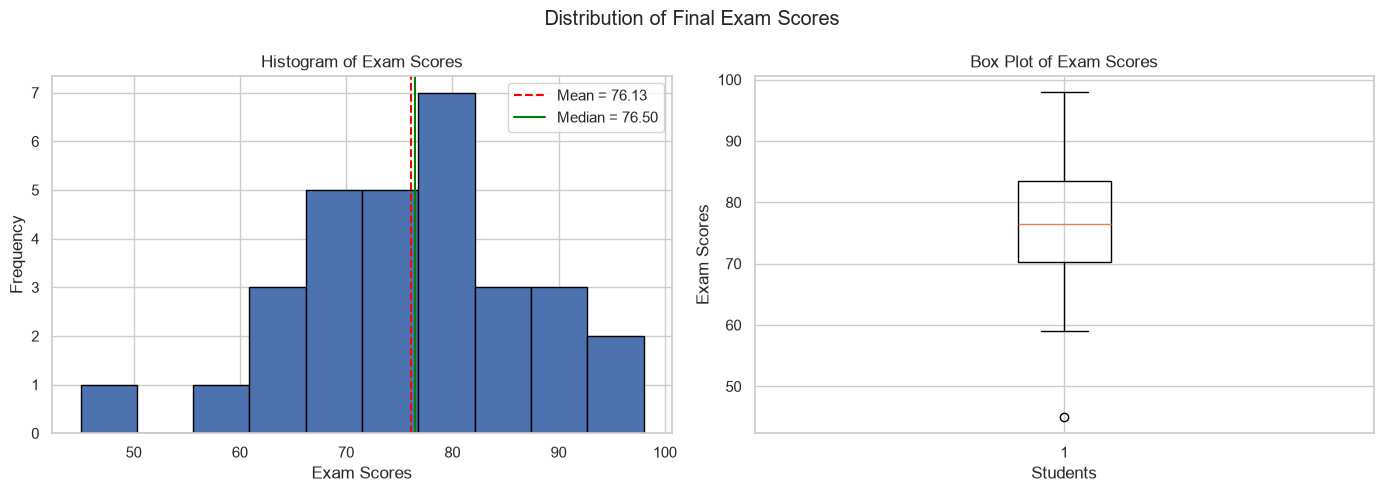

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate mean and median
mean = np.mean(scores)
median = np.median(scores)

# Create figure with two subplots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram
ax[0].hist(scores, bins=10, edgecolor='black')
ax[0].axvline(mean, color='red', linestyle='--',
              label=f'Mean = {mean:.2f}')
ax[0].axvline(median, color='green', linestyle='-',
              label=f'Median = {median:.2f}')

ax[0].set_title('Histogram of Exam Scores')
ax[0].set_xlabel('Exam Scores')
ax[0].set_ylabel('Frequency')
ax[0].legend()

# Right: Box Plot
ax[1].boxplot(scores)
ax[1].set_title('Box Plot of Exam Scores')
ax[1].set_xlabel('Students')
ax[1].set_ylabel('Exam Scores')

# Overall title
fig.suptitle('Distribution of Final Exam Scores')

plt.tight_layout()
plt.show()


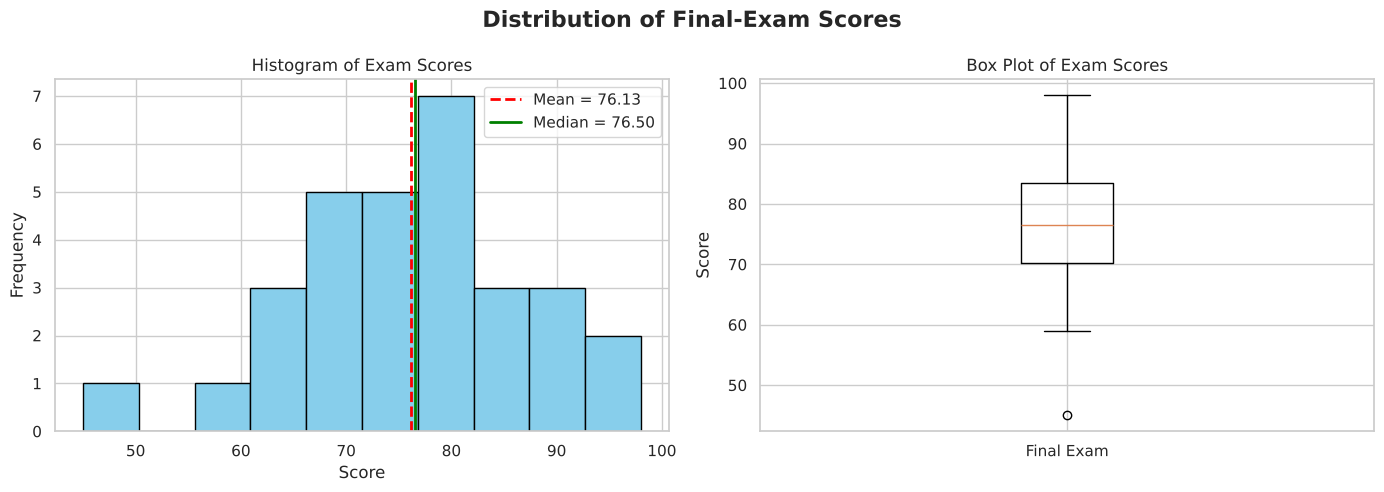

In [3]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The distribution is slightly left-skewed (negatively skewed), as the lower scores extend further from the center.

The outlier from A1 (45) appears as a separate point below the lower whisker in the box plot.

### Exercise A3 — Comparing Two Distributions (2 points)
Two sections took the same quiz:

```python
section_1 = [78, 82, 75, 80, 85, 79, 77, 83, 81, 76, 74, 88, 79,
             82, 80, 84, 73, 78, 86, 81, 77, 79, 83, 80, 76]
section_2 = [65, 92, 70, 98, 74, 61, 88, 95, 68, 72, 99, 64, 85,
             90, 66, 71, 97, 63, 80, 94, 67, 89, 60, 96, 69]
```
1. Use the **Shapiro-Wilk test** to check whether each section follows a normal distribution (α = 0.05).
2. Use **Student's t-test** (`ttest_ind`) and the **Mann-Whitney U test** (`mannwhitneyu`) to check whether the two sections have equal means. Print each p-value and the decision (reject / fail to reject H₀).
3. Draw **side-by-side box plots** of the two sections with a title and labelled ticks.

Based on the tests **and** the box plots, are the two sections similar? Explain why the box plot tells you something the t-test does not.

Shapiro-Wilk Normality Test
Section 1: p-value = 0.9911 | Fail to reject H0
Section 2: p-value = 0.0101 | Reject H0

Student's t-test
p-value = 0.7468
Decision: Fail to reject H0

Mann-Whitney U Test
p-value = 0.6274
Decision: Fail to reject H0


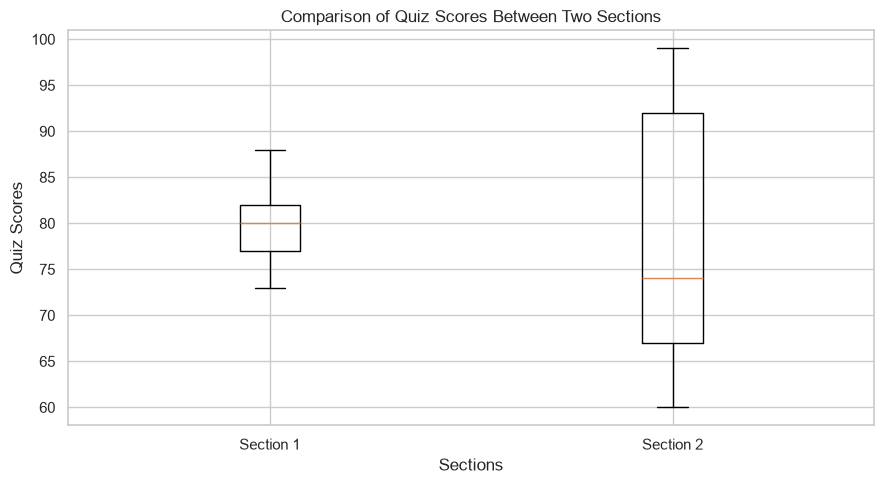

In [5]:
from scipy.stats import shapiro, ttest_ind, mannwhitneyu

section_1 = [78, 82, 75, 80, 85, 79, 77, 83, 81, 76, 74, 88, 79,
             82, 80, 84, 73, 78, 86, 81, 77, 79, 83, 80, 76]
section_2 = [65, 92, 70, 98, 74, 61, 88, 95, 68, 72, 99, 64, 85,
             90, 66, 71, 97, 63, 80, 94, 67, 89, 60, 96, 69]


import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro, ttest_ind, mannwhitneyu

section_1 = [78, 82, 75, 80, 85, 79, 77, 83, 81, 76, 74, 88, 79,
             82, 80, 84, 73, 78, 86, 81, 77, 79, 83, 80, 76]

section_2 = [65, 92, 70, 98, 74, 61, 88, 95, 68, 72, 99, 64, 85,
             90, 66, 71, 97, 63, 80, 94, 67, 89, 60, 96, 69]

alpha = 0.05

# 1. Shapiro-Wilk Normality Test
print("Shapiro-Wilk Normality Test")

for name, data in [("Section 1", section_1), ("Section 2", section_2)]:
    stat, p = shapiro(data)
    decision = "Reject H0" if p < alpha else "Fail to reject H0"
    print(f"{name}: p-value = {p:.4f} | {decision}")

# 2. Student's t-test
t_stat, t_p = ttest_ind(section_1, section_2)

print("\nStudent's t-test")
print(f"p-value = {t_p:.4f}")
print("Decision:", "Reject H0" if t_p < alpha else "Fail to reject H0")

# Mann-Whitney U Test
u_stat, u_p = mannwhitneyu(section_1, section_2, alternative='two-sided')

print("\nMann-Whitney U Test")
print(f"p-value = {u_p:.4f}")
print("Decision:", "Reject H0" if u_p < alpha else "Fail to reject H0")

# 3. Side-by-Side Box Plots
plt.figure(figsize=(9, 5))

plt.boxplot([section_1, section_2],
            tick_labels=['Section 1', 'Section 2'])

plt.title('Comparison of Quiz Scores Between Two Sections')
plt.xlabel('Sections')
plt.ylabel('Quiz Scores')

plt.tight_layout()
plt.show()



**Your Answer:**

The two sections have similar average scores, and the t-test does not show a statistically significant difference between their means.

However, the box plots show that Section 1 has a smaller spread, while Section 2 has much greater variability.

Therefore, the sections are similar in their average performance but different in score consistency. The box plot reveals differences in spread and distribution that the t-test does not show.

---
## Part B — Data Cleaning and Preparation

### Exercise B1 — Cleaning a Messy Dataset (3 points)
The DataFrame below was collected by several people and contains typical data problems. Clean it by applying the following steps **in order**, then display the cleaned DataFrame:

1. **Remove duplicate** rows.
2. **Fix structural errors** in `City`: remove extra spaces and use title case (e.g. `' riyadh'` → `'Riyadh'`).
3. **Filter noisy data:** an age cannot be negative, so replace negative `Age` values with their absolute value.
4. **Wrangle inconsistent units:** some `Attendance` values were entered as fractions (e.g. `0.95`) instead of percentages. Convert any value ≤ 1 to a percentage.
5. **Standardize units:** create `Height_cm` from `Height_in` (1 in = 2.54 cm, rounded to 1 decimal) and **drop** `Height_in` (irrelevant once converted).
6. **Handle missing values:** fill `Age` with the **mean** (rounded to 0 decimals), `GPA` with the **median**, and `City` with the **mode**.
7. Reset the index (`drop=True`) and display the result.

In [7]:
data = {
    'Student':    ['Ali', 'Sara', 'Omar', 'Sara', 'Huda', 'Khalid', 'Mona', 'Yousef', 'Lina', 'Faisal'],
    'City':       ['Riyadh', ' riyadh', 'Jeddah', ' riyadh', 'DAMMAM', 'Jeddah ', 'riyadh', ' Riyadh', None, 'jeddah'],
    'Age':        [21, 22, np.nan, 22, 20, 23, -21, 24, 22, 21],
    'Height_in':  [70, 64, 68, 64, 62, 72, 61, 69, 63, 71],
    'GPA':        [3.2, 3.8, 2.9, 3.8, 3.5, np.nan, 3.6, 2.7, 3.9, 3.1],
    'Attendance': [0.95, 92, 88, 92, 97, 85, 90, 0.78, 99, 91]
}
df = pd.DataFrame(data)
display(df)


import pandas as pd
import numpy as np

# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Fix structural errors in City
df['City'] = df['City'].str.strip().str.title()

# 3. Fix negative Age values
df['Age'] = df['Age'].abs()

# 4. Convert fractional Attendance to percentages
df['Attendance'] = np.where(
    df['Attendance'] <= 1,
    df['Attendance'] * 100,
    df['Attendance']
)

# 5. Convert Height_in to Height_cm
df['Height_cm'] = (df['Height_in'] * 2.54).round(1)
df = df.drop(columns=['Height_in'])

# 6. Handle missing values
df['Age'] = df['Age'].fillna(round(df['Age'].mean(), 0))
df['GPA'] = df['GPA'].fillna(df['GPA'].median())
df['City'] = df['City'].fillna(df['City'].mode()[0])

# 7. Reset index and display
df = df.reset_index(drop=True)

display(df)



,Student,City,Age,Height_in,GPA,Attendance
0,Ali,Riyadh,21.0,70,3.2,0.95
1,Sara,riyadh,22.0,64,3.8,92.00
2,Omar,Jeddah,NaN,68,2.9,88.00
3,Sara,riyadh,22.0,64,3.8,92.00
4,Huda,DAMMAM,20.0,62,3.5,97.00
5,Khalid,Jeddah,23.0,72,NaN,85.00
6,Mona,riyadh,-21.0,61,3.6,90.00
7,Yousef,Riyadh,24.0,69,2.7,0.78
8,Lina,NaN,22.0,63,3.9,99.00
9,Faisal,jeddah,21.0,71,3.1,91.00


,Student,City,Age,GPA,Attendance,Height_cm
0,Ali,Riyadh,21.0,3.20,95.0,177.8
1,Sara,Riyadh,22.0,3.80,92.0,162.6
2,Omar,Jeddah,22.0,2.90,88.0,172.7
3,Huda,Dammam,20.0,3.50,97.0,157.5
4,Khalid,Jeddah,23.0,3.35,85.0,182.9
5,Mona,Riyadh,21.0,3.60,90.0,154.9
6,Yousef,Riyadh,24.0,2.70,78.0,175.3
7,Lina,Riyadh,22.0,3.90,99.0,160.0
8,Faisal,Jeddah,21.0,3.10,91.0,180.3


In [5]:
# The output generated by the code written to answer this question should be as follows:

,Student,City,Age,Height_in,GPA,Attendance
0,Ali,Riyadh,21.0,70,3.2,0.95
1,Sara,riyadh,22.0,64,3.8,92.00
2,Omar,Jeddah,NaN,68,2.9,88.00
3,Sara,riyadh,22.0,64,3.8,92.00
4,Huda,DAMMAM,20.0,62,3.5,97.00
5,Khalid,Jeddah,23.0,72,NaN,85.00
6,Mona,riyadh,-21.0,61,3.6,90.00
7,Yousef,Riyadh,24.0,69,2.7,0.78
8,Lina,NaN,22.0,63,3.9,99.00
9,Faisal,jeddah,21.0,71,3.1,91.00


,Student,City,Age,GPA,Attendance,Height_cm
0,Ali,Riyadh,21.0,3.20,95.0,177.8
1,Sara,Riyadh,22.0,3.80,92.0,162.6
2,Omar,Jeddah,22.0,2.90,88.0,172.7
3,Huda,Dammam,20.0,3.50,97.0,157.5
4,Khalid,Jeddah,23.0,3.35,85.0,182.9
5,Mona,Riyadh,21.0,3.60,90.0,154.9
6,Yousef,Riyadh,24.0,2.70,78.0,175.3
7,Lina,Riyadh,22.0,3.90,99.0,160.0
8,Faisal,Jeddah,21.0,3.10,91.0,180.3


### Exercise B2 — Detecting and Treating Outliers (2 points)
The cell below generates 200 apartment prices (in SAR 1000s) plus a few extreme values.
1. Use the **IQR method** to compute the lower and upper bounds and print **how many outliers** there are.
2. Treat the outliers by **capping (winsorization)** at the **5th and 95th percentiles** (`np.clip`). Print the new min and max.
3. Draw **two box plots side by side** (1 × 2 subplots): *Before capping* and *After capping*. Add titles and a y-label.

Lower Bound: 167.85
Upper Bound: 540.65
Number of Outliers: 4

New Minimum: 258.23
New Maximum: 465.26


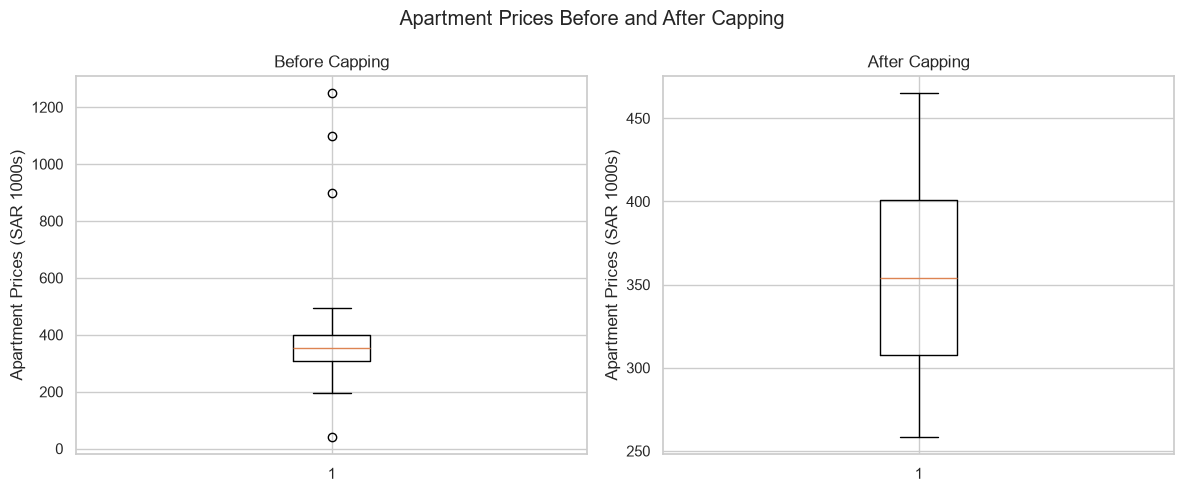

In [8]:
np.random.seed(0)
prices = np.concatenate([np.random.normal(350, 60, 200), [900, 1100, 40, 1250]])


import numpy as np
import matplotlib.pyplot as plt

# Use the apartment prices generated in the previous cell
prices = np.array(prices)

# 1. Detect outliers using the IQR method
Q1 = np.percentile(prices, 25)
Q3 = np.percentile(prices, 75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = prices[(prices < lower_bound) | (prices > upper_bound)]

print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Number of Outliers: {len(outliers)}")

# 2. Cap values at the 5th and 95th percentiles
p5 = np.percentile(prices, 5)
p95 = np.percentile(prices, 95)

prices_capped = np.clip(prices, p5, p95)

print(f"\nNew Minimum: {np.min(prices_capped):.2f}")
print(f"New Maximum: {np.max(prices_capped):.2f}")

# 3. Side-by-side box plots
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].boxplot(prices)
ax[0].set_title('Before Capping')
ax[0].set_ylabel('Apartment Prices (SAR 1000s)')

ax[1].boxplot(prices_capped)
ax[1].set_title('After Capping')
ax[1].set_ylabel('Apartment Prices (SAR 1000s)')

fig.suptitle('Apartment Prices Before and After Capping')

plt.tight_layout()
plt.show()



Lower bound = 167.85, Upper bound = 540.65
Number of outliers: 4
After capping: min = 258.23, max = 465.26


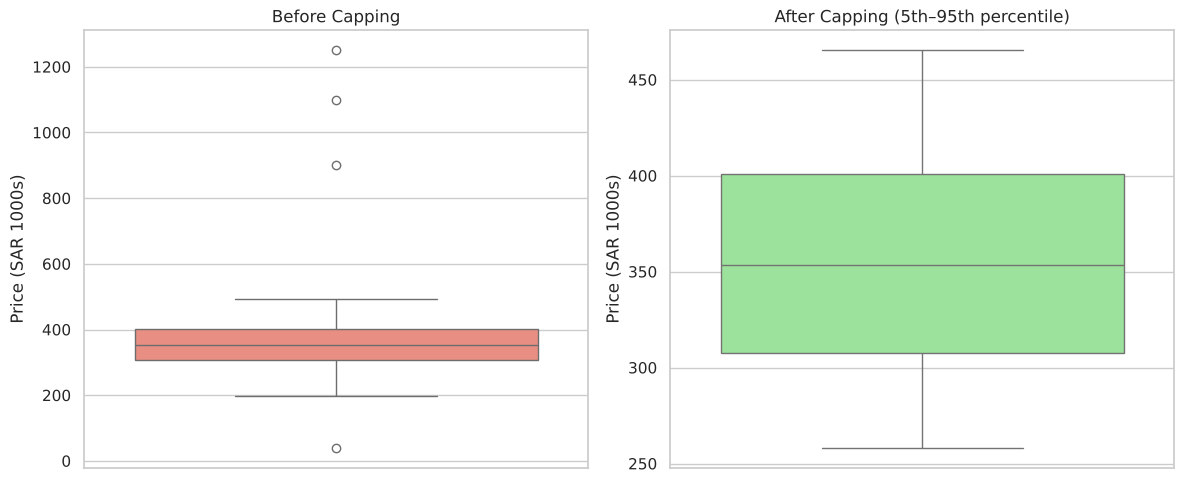

In [6]:
# The output generated by the code written to answer this question should be as follows:

### Exercise B3 — Data Transformation (2 points)
The cell below generates 500 right-skewed household incomes. Create three new versions of the data:
- **Normalized** to the range [0, 1] using `MinMaxScaler`
- **Standardized** (mean 0, std 1) using `StandardScaler`
- **Log-transformed** using `np.log`

Plot the **four** versions (original + three transformed) as histograms in a **2 × 2 subplot grid** with 30 bins each, a title on every subplot, and an overall title.

Which transformation changes the **shape** of the distribution, and which ones only change the **scale**?

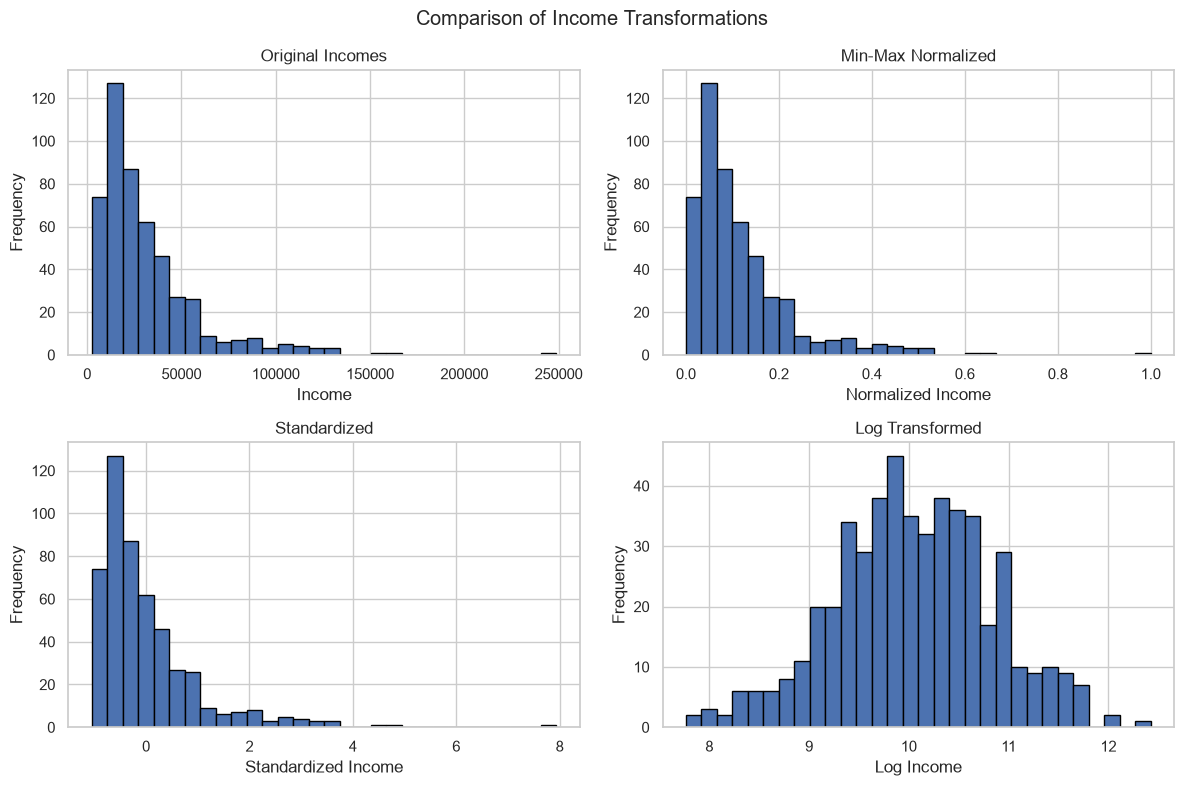

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler

np.random.seed(1)
income = pd.DataFrame({'Income': np.random.lognormal(mean=10, sigma=0.8, size=500)})

# Original income data
incomes = income[['Income']].values

# 1. Min-Max Normalization
normalized = MinMaxScaler().fit_transform(incomes).flatten()

# 2. Standardization
standardized = StandardScaler().fit_transform(incomes).flatten()

# 3. Log Transformation
log_transformed = np.log(incomes.flatten())

# 4. Plot Histograms
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].hist(incomes.flatten(), bins=30, edgecolor='black')
ax[0, 0].set_title('Original Incomes')
ax[0, 0].set_xlabel('Income')
ax[0, 0].set_ylabel('Frequency')

ax[0, 1].hist(normalized, bins=30, edgecolor='black')
ax[0, 1].set_title('Min-Max Normalized')
ax[0, 1].set_xlabel('Normalized Income')
ax[0, 1].set_ylabel('Frequency')

ax[1, 0].hist(standardized, bins=30, edgecolor='black')
ax[1, 0].set_title('Standardized')
ax[1, 0].set_xlabel('Standardized Income')
ax[1, 0].set_ylabel('Frequency')

ax[1, 1].hist(log_transformed, bins=30, edgecolor='black')
ax[1, 1].set_title('Log Transformed')
ax[1, 1].set_xlabel('Log Income')
ax[1, 1].set_ylabel('Frequency')

fig.suptitle('Comparison of Income Transformations')

plt.tight_layout()
plt.show()



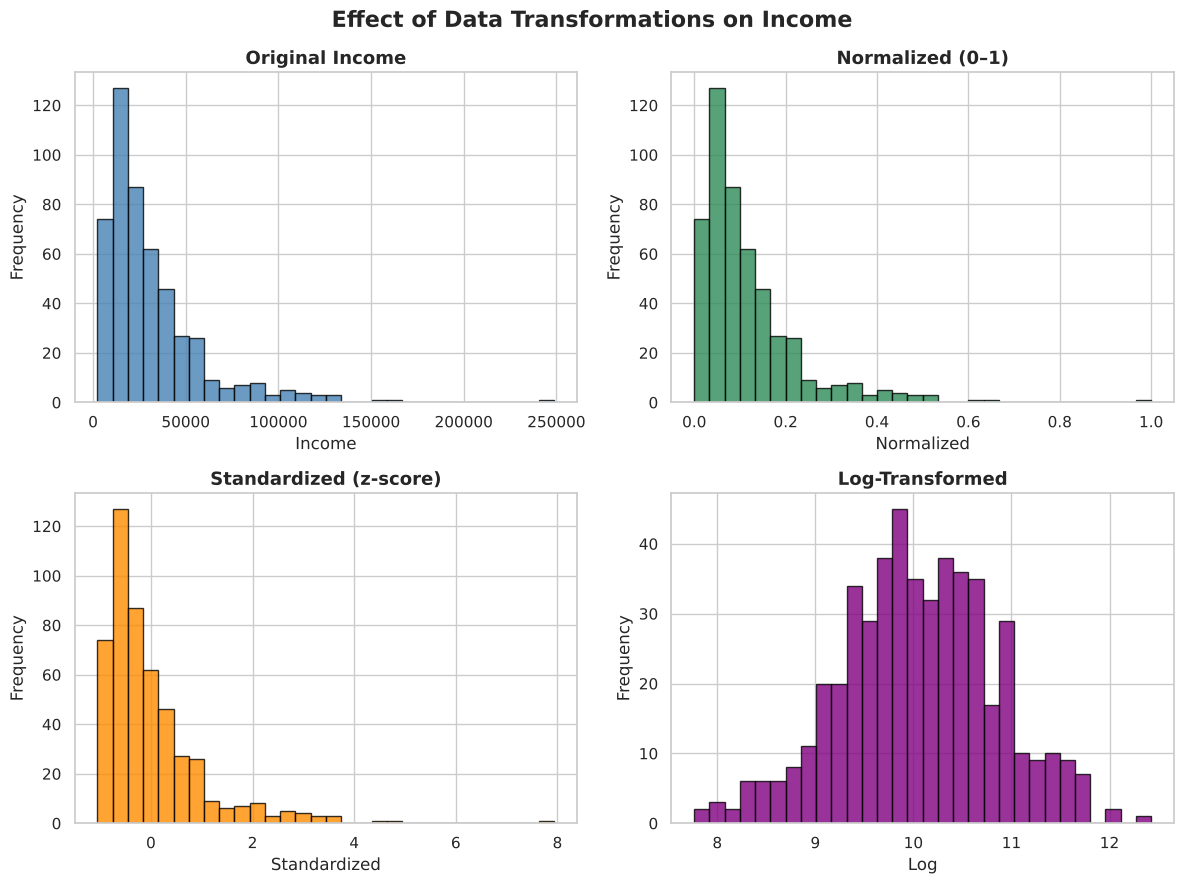

In [7]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The log transformation changes the shape of the distribution by reducing right skewness and making it more symmetric.

Min-Max normalization and standardization only change the scale of the data without changing the shape of the distribution.

### Exercise B4 — Encoding Categorical Variables (2 points)
For the product table below:
1. `Size` is **ordinal**. Use a mapping dictionary to encode it as `Small → 1`, `Medium → 2`, `Large → 3`.
2. `In_Stock` is **binary**. Use `LabelEncoder` to encode it (`No → 0`, `Yes → 1`).
3. `Color` is **nominal**. Apply **one-hot encoding** with `pd.get_dummies` (`drop_first=True`, `dtype=int`).

Display the encoded DataFrame. Why is one-hot encoding (and not label encoding) the right choice for `Color`?

In [12]:

import pandas as pd
from sklearn.preprocessing import LabelEncoder

# 1. Ordinal Encoding for Size
size_mapping = {'Small': 1, 'Medium': 2, 'Large': 3}
products['Size'] = products['Size'].map(size_mapping)

# 2. Label Encoding for In_Stock
le = LabelEncoder()
products['In_Stock'] = le.fit_transform(products['In_Stock'])

# 3. One-Hot Encoding for Color
products_encoded = pd.get_dummies(
    products,
    columns=['Color'],
    drop_first=True,
    dtype=int
)

# Display encoded DataFrame
display(products_encoded)



,Product,Size,In_Stock,Price,Color_Green,Color_Red
0,T-shirt,1,1,45,0,1
1,Jacket,3,0,220,0,0
2,Cap,2,1,35,1,0
3,Hoodie,3,1,150,0,1
4,Scarf,1,0,60,1,0
5,Jeans,2,1,180,0,0


In [8]:
# The output generated by the code written to answer this question should be as follows:

,Product,Size,Color,In_Stock,Price
0,T-shirt,Small,Red,Yes,45
1,Jacket,Large,Blue,No,220
2,Cap,Medium,Green,Yes,35
3,Hoodie,Large,Red,Yes,150
4,Scarf,Small,Green,No,60
5,Jeans,Medium,Blue,Yes,180


,Product,Size,In_Stock,Price,Color_Green,Color_Red
0,T-shirt,1,1,45,0,1
1,Jacket,3,0,220,0,0
2,Cap,2,1,35,1,0
3,Hoodie,3,1,150,0,1
4,Scarf,1,0,60,1,0
5,Jeans,2,1,180,0,0


**Your Answer:**

One-hot encoding is appropriate for Color because colors are nominal categories with no natural order. Label encoding would incorrectly imply a ranking between colors, while one-hot encoding represents each color without introducing an artificial order.

---
## Part C — Advanced Plotting with Matplotlib & Seaborn (Penguins Dataset)

Load the built-in `penguins` dataset and drop the rows with missing values:
```python
penguins = sns.load_dataset('penguins').dropna()
```

### Exercise C1 — Subplots: Combining Matplotlib and Seaborn (2 points)
Create a **2 × 2 grid of subplots** (`figsize=(14, 10)`) and draw a **Seaborn** plot in each panel using the `ax=` argument:
- **[0, 0]** Histogram of `flipper_length_mm` with 20 bins and a KDE curve
- **[0, 1]** Scatter plot of `bill_length_mm` (x) vs `bill_depth_mm` (y), colored by `species`
- **[1, 0]** Bar plot of the mean `body_mass_g` per `species`
- **[1, 1]** Box plot of `body_mass_g` per `species`, split by `sex` (`hue`)

Give each subplot its own title, add an overall title (`fig.suptitle`) and use `plt.tight_layout()`.

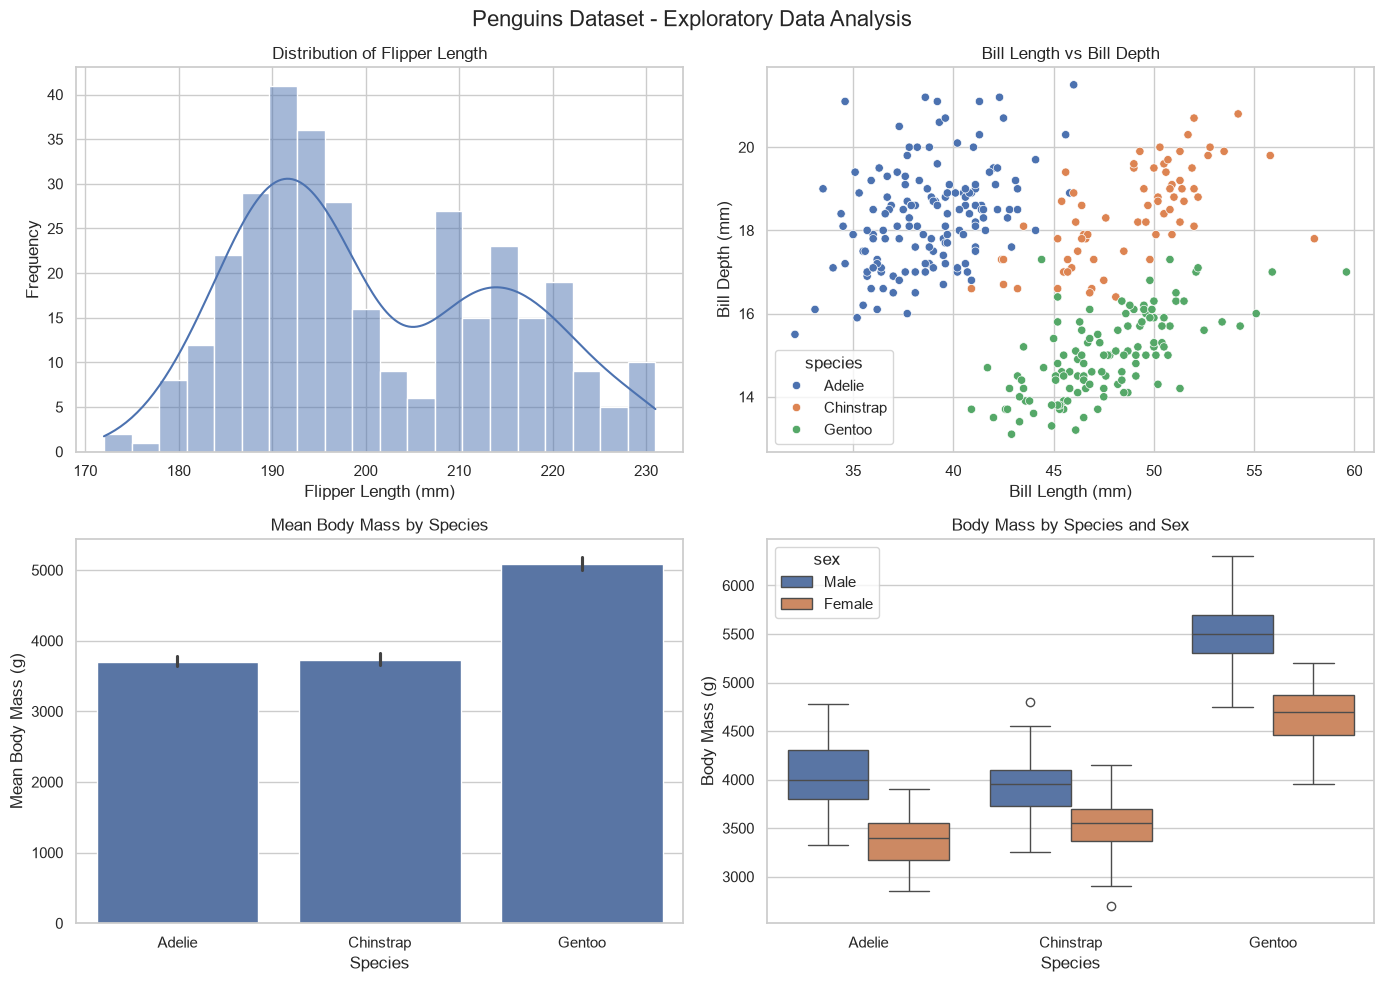

In [13]:
penguins = sns.load_dataset('penguins').dropna()


import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean the dataset
penguins = sns.load_dataset('penguins').dropna()

# Create 2x2 subplots
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# [0, 0] Histogram with KDE
sns.histplot(data=penguins, x='flipper_length_mm',
             bins=20, kde=True, ax=ax[0, 0])
ax[0, 0].set_title('Distribution of Flipper Length')
ax[0, 0].set_xlabel('Flipper Length (mm)')
ax[0, 0].set_ylabel('Frequency')

# [0, 1] Scatter Plot
sns.scatterplot(data=penguins, x='bill_length_mm',
                y='bill_depth_mm', hue='species',
                ax=ax[0, 1])
ax[0, 1].set_title('Bill Length vs Bill Depth')
ax[0, 1].set_xlabel('Bill Length (mm)')
ax[0, 1].set_ylabel('Bill Depth (mm)')

# [1, 0] Bar Plot
sns.barplot(data=penguins, x='species',
            y='body_mass_g', ax=ax[1, 0])
ax[1, 0].set_title('Mean Body Mass by Species')
ax[1, 0].set_xlabel('Species')
ax[1, 0].set_ylabel('Mean Body Mass (g)')

# [1, 1] Box Plot
sns.boxplot(data=penguins, x='species',
            y='body_mass_g', hue='sex',
            ax=ax[1, 1])
ax[1, 1].set_title('Body Mass by Species and Sex')
ax[1, 1].set_xlabel('Species')
ax[1, 1].set_ylabel('Body Mass (g)')

# Overall title
fig.suptitle('Penguins Dataset - Exploratory Data Analysis',
             fontsize=16)

plt.tight_layout()
plt.show()



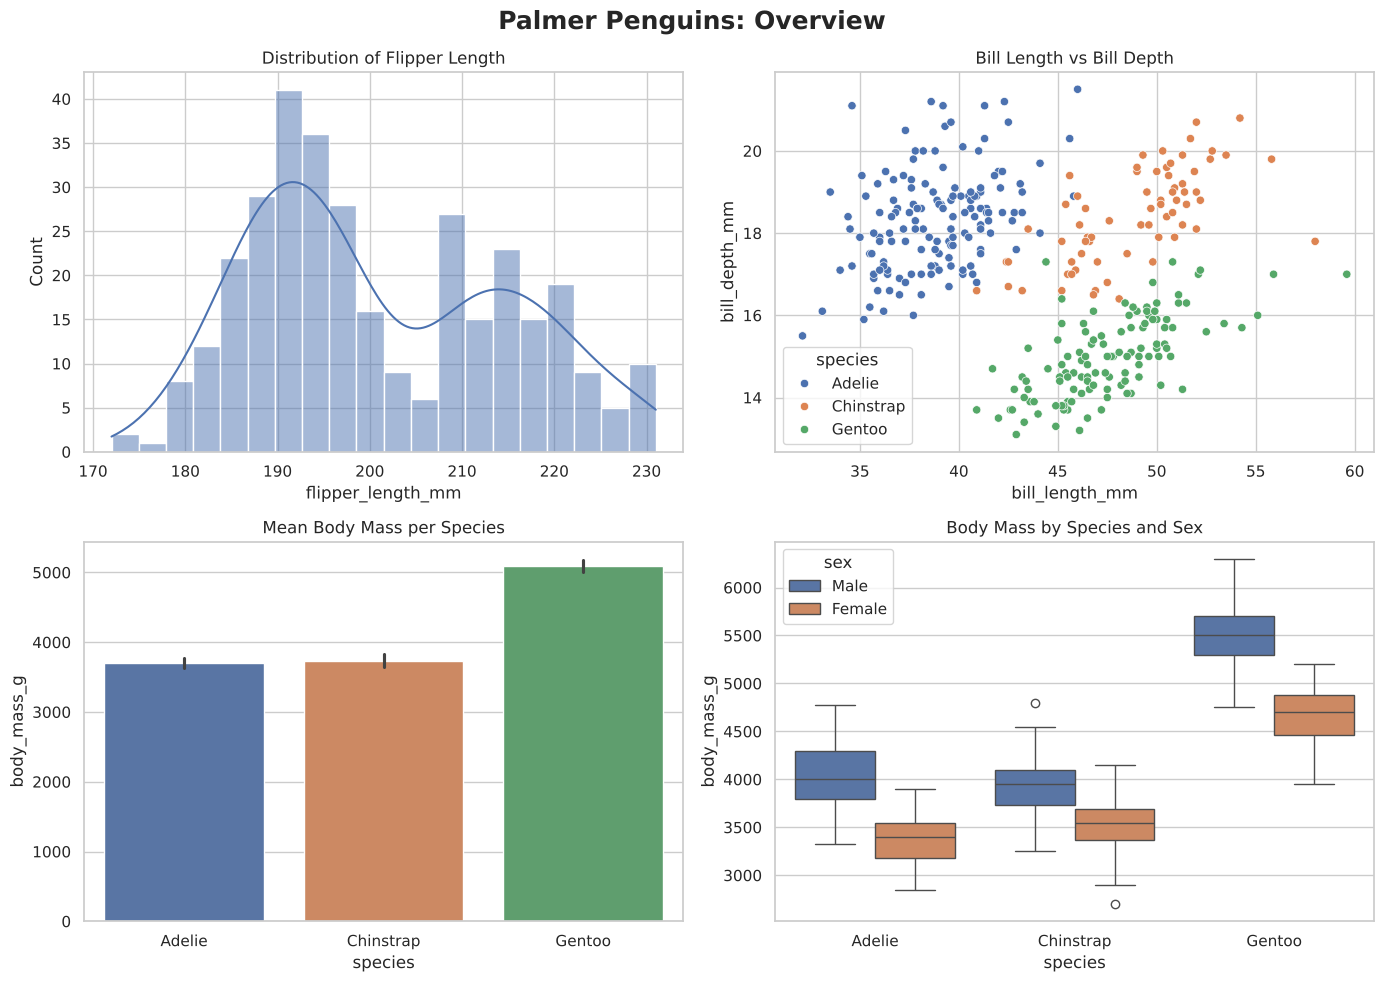

In [9]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C2 — Correlation Heatmap (2 points)
Compute the **Pearson correlation matrix** of the four numeric columns of `penguins` and display it as a Seaborn **heatmap** with:
- the values annotated with 2 decimal places (`annot=True`, `fmt='.2f'`)
- the **diverging** colormap `'coolwarm'` with `vmin=-1`, `vmax=1`
- `linewidths=0.5` and a colorbar label `'Pearson r'`
- a title and `figsize=(8, 6)`

Which pair of variables has the **strongest positive** correlation, and which pair has the **strongest negative** correlation?

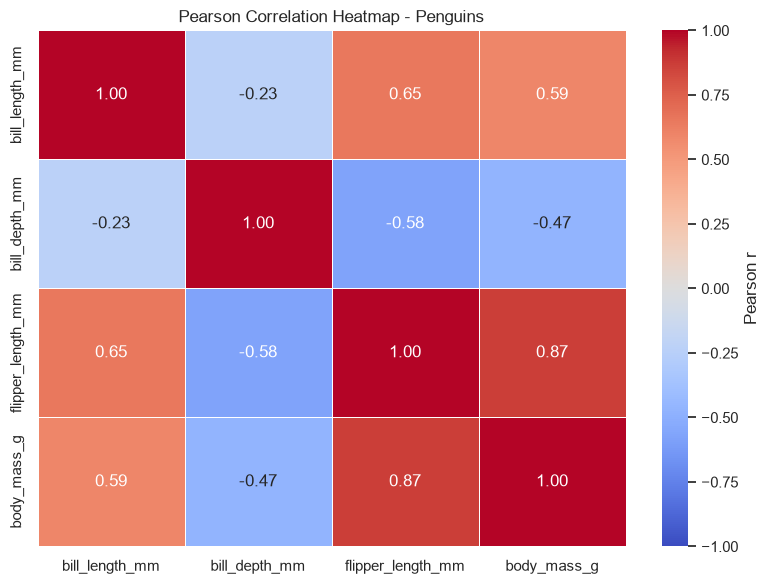

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean the dataset
penguins = sns.load_dataset('penguins').dropna()

# Select numeric columns
numeric_cols = ['bill_length_mm', 'bill_depth_mm',
                'flipper_length_mm', 'body_mass_g']

# Calculate Pearson correlation matrix
corr_matrix = penguins[numeric_cols].corr(method='pearson')

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(corr_matrix, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5,
            cbar_kws={'label': 'Pearson r'})

plt.title('Pearson Correlation Heatmap - Penguins')
plt.tight_layout()
plt.show()



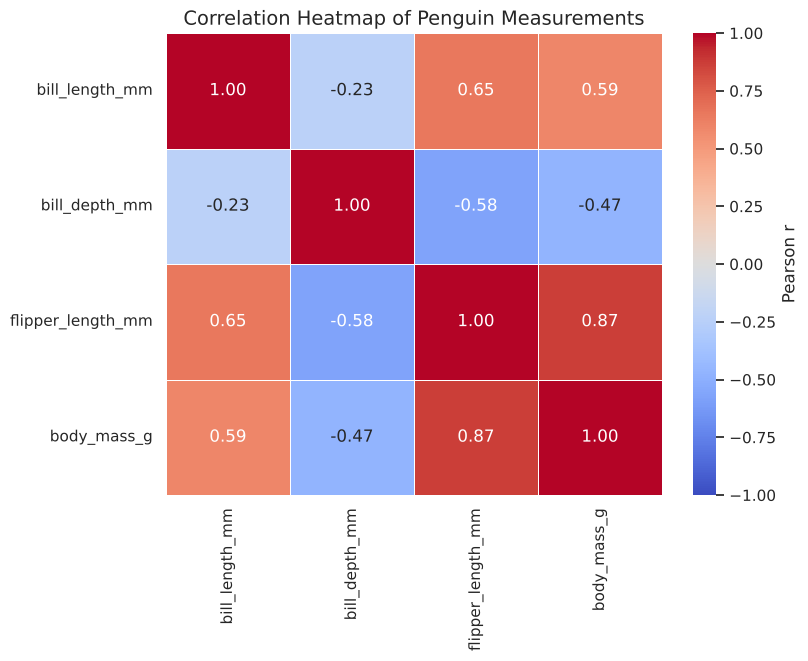

In [10]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The strongest positive correlation is between flipper length and body mass (r ≈ 0.87).

The strongest negative correlation is between bill depth and flipper length (r ≈ -0.58).

### Exercise C3 — Colormaps and Colorbars (2 points)
1. Using **Matplotlib** (`plt.scatter`), plot `flipper_length_mm` (x) vs `body_mass_g` (y), with the point colors given by `bill_length_mm` using the **sequential** colormap `'viridis'`. Add a **colorbar** labelled `'Bill Length (mm)'`, axis labels and a title.
2. In the **Your Answer** cell, state which **type of colormap** (sequential, diverging, cyclic or qualitative) you would use for each case, and name one example colormap for each:
   - (a) Temperature anomaly (°C above or below the long-term average)
   - (b) Population density of cities
   - (c) Wind direction (0°–360°)
   - (d) Blood type (A, B, AB, O)

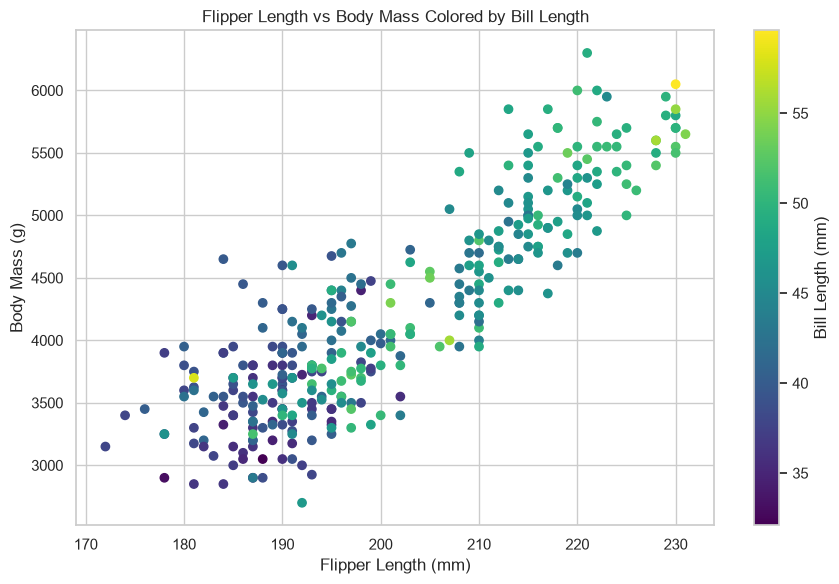

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean the dataset
penguins = sns.load_dataset('penguins').dropna()

# Create scatter plot
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    penguins['flipper_length_mm'],
    penguins['body_mass_g'],
    c=penguins['bill_length_mm'],
    cmap='viridis'
)

# Add colorbar
plt.colorbar(scatter, label='Bill Length (mm)')

# Labels and title
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.title('Flipper Length vs Body Mass Colored by Bill Length')

plt.tight_layout()
plt.show()



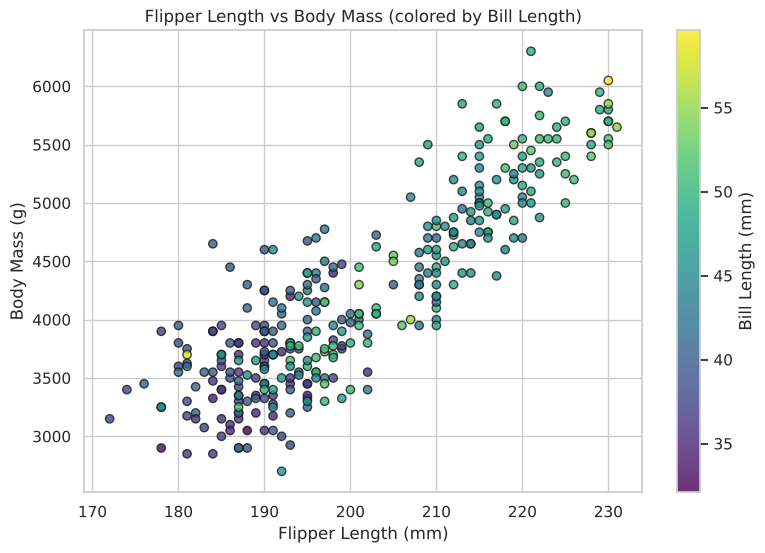

In [11]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

**(a) Temperature anomaly:** Diverging colormap — `coolwarm`

**(b) Population density of cities:** Sequential colormap — `viridis`

**(c) Wind direction (0°–360°):** Cyclic colormap — `twilight`

**(d) Blood type (A, B, AB, O):** Qualitative colormap — `tab10`

### Exercise C4 — 3D Surface Plot and Contour Plot (2 points)
For the function $z = \sin\left(\sqrt{x^2 + y^2}\right)$ with $x, y \in [-6, 6]$ (use `np.linspace(-6, 6, 200)` and `np.meshgrid`), create **one figure** (`figsize=(15, 6)`) with two panels:
- **Left:** a **3D surface plot** (`projection='3d'`, `plot_surface`) using the colormap `'plasma'`
- **Right:** a **filled contour plot** (`contourf`, 20 levels, same colormap) with a **colorbar**

Label the x, y (and z) axes and give each panel a title.

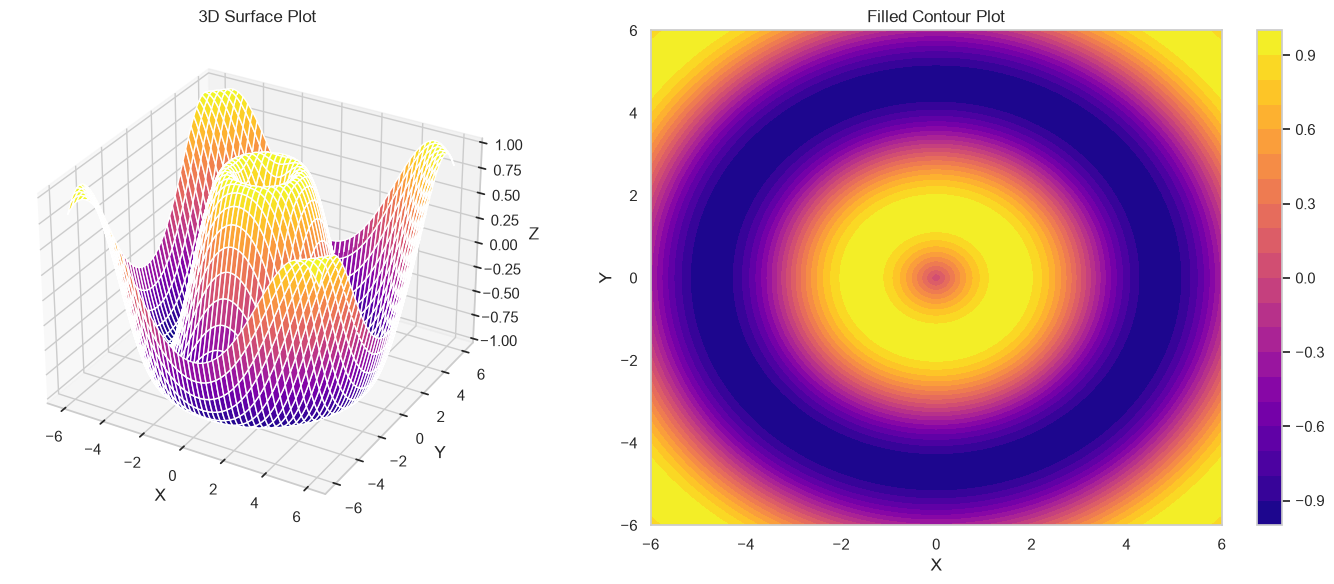

In [16]:

import numpy as np
import matplotlib.pyplot as plt

# Create x and y values
x = np.linspace(-6, 6, 200)
y = np.linspace(-6, 6, 200)

# Create meshgrid
X, Y = np.meshgrid(x, y)

# Calculate Z
Z = np.sin(np.sqrt(X**2 + Y**2))

# Create figure with two panels
fig = plt.figure(figsize=(15, 6))

# Left: 3D Surface Plot
ax1 = fig.add_subplot(1, 2, 1, projection='3d')

ax1.plot_surface(X, Y, Z, cmap='plasma')

ax1.set_title('3D Surface Plot')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# Right: Filled Contour Plot
ax2 = fig.add_subplot(1, 2, 2)

contour = ax2.contourf(X, Y, Z, levels=20, cmap='plasma')

fig.colorbar(contour, ax=ax2)

ax2.set_title('Filled Contour Plot')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')

plt.tight_layout()
plt.show()



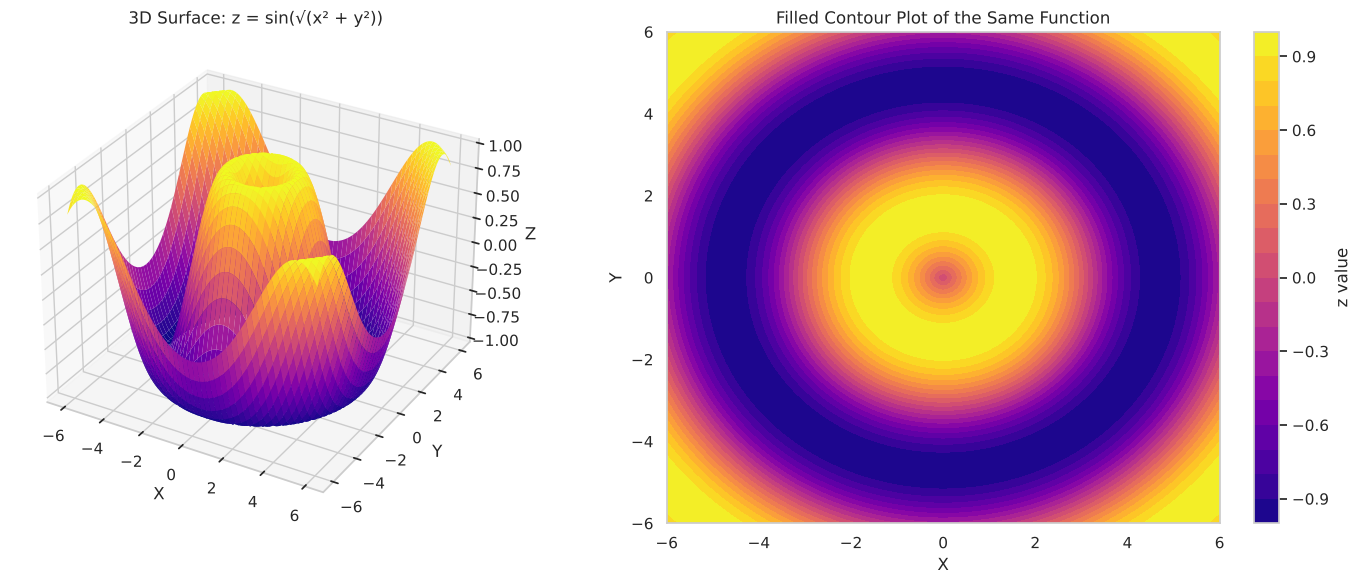

In [12]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C5 — Customizing Labels, Fonts, Ticks and Legends (2 points)
Using the `flights` dataset, plot the monthly number of passengers for the years **1949**, **1954** and **1960** as three lines on the same axes (`figsize=(11, 6)`), with a different marker for each year. Then customize the plot:
- Title using `fontdict` with size **16**, **bold** and **italic**
- Axis labels with font size **13** and **bold** weight
- x-tick labels rotated **45°**
- Legend with the title `'Year'`, placed at `loc='upper left'`, `fontsize=11` and **no frame** (`frameon=False`)
- **Annotate** the peak month of 1960 with an arrow and the text `'Peak: <value>'` (look up `plt.annotate`)

*Hint:* `flights.pivot(index='month', columns='year', values='passengers')` gives one column per year.

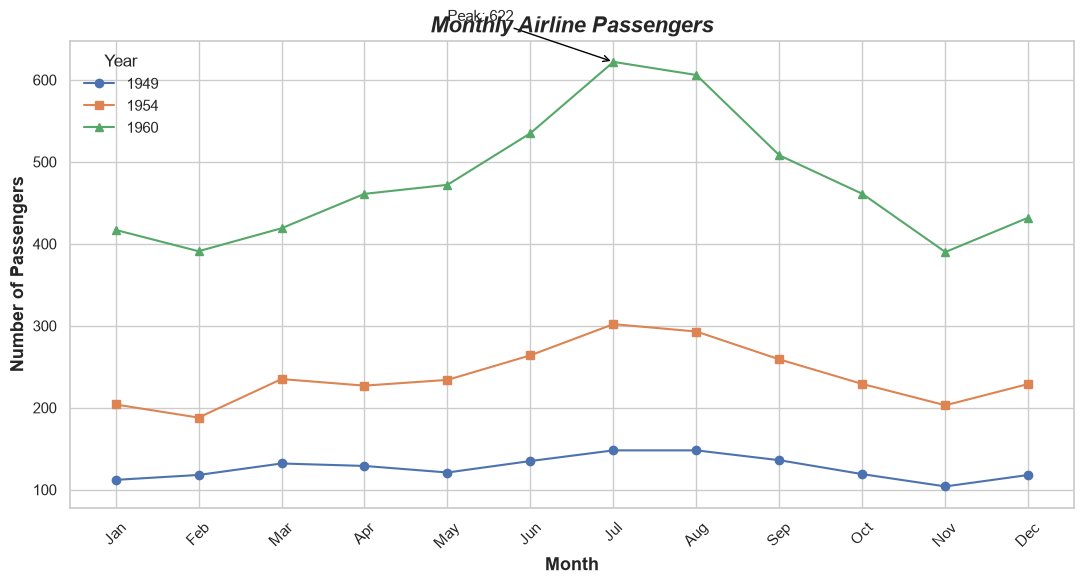

In [17]:
flights = sns.load_dataset('flights')


import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Load flights dataset
flights = sns.load_dataset('flights')

# Pivot the data
flights_pivot = flights.pivot(
    index='month',
    columns='year',
    values='passengers'
)

# Create figure
plt.figure(figsize=(11, 6))

# Plot three years with different markers
plt.plot(flights_pivot.index, flights_pivot[1949],
         marker='o', label='1949')

plt.plot(flights_pivot.index, flights_pivot[1954],
         marker='s', label='1954')

plt.plot(flights_pivot.index, flights_pivot[1960],
         marker='^', label='1960')

# Customize title
plt.title('Monthly Airline Passengers',
          fontdict={'fontsize': 16,
                    'fontweight': 'bold',
                    'fontstyle': 'italic'})

# Customize axis labels
plt.xlabel('Month', fontsize=13, fontweight='bold')
plt.ylabel('Number of Passengers', fontsize=13, fontweight='bold')

# Rotate x-tick labels
plt.xticks(rotation=45)

# Customize legend
plt.legend(title='Year', loc='upper left',
           fontsize=11, frameon=False)

# Find peak month of 1960
peak_value = flights_pivot[1960].max()
peak_month = flights_pivot[1960].idxmax()
peak_index = flights_pivot.index.get_loc(peak_month)

# Annotate peak with arrow
plt.annotate(
    f'Peak: {peak_value}',
    xy=(peak_index, peak_value),
    xytext=(peak_index - 2, peak_value + 50),
    arrowprops=dict(arrowstyle='->', color='black'),
    fontsize=11
)

plt.tight_layout()
plt.show()



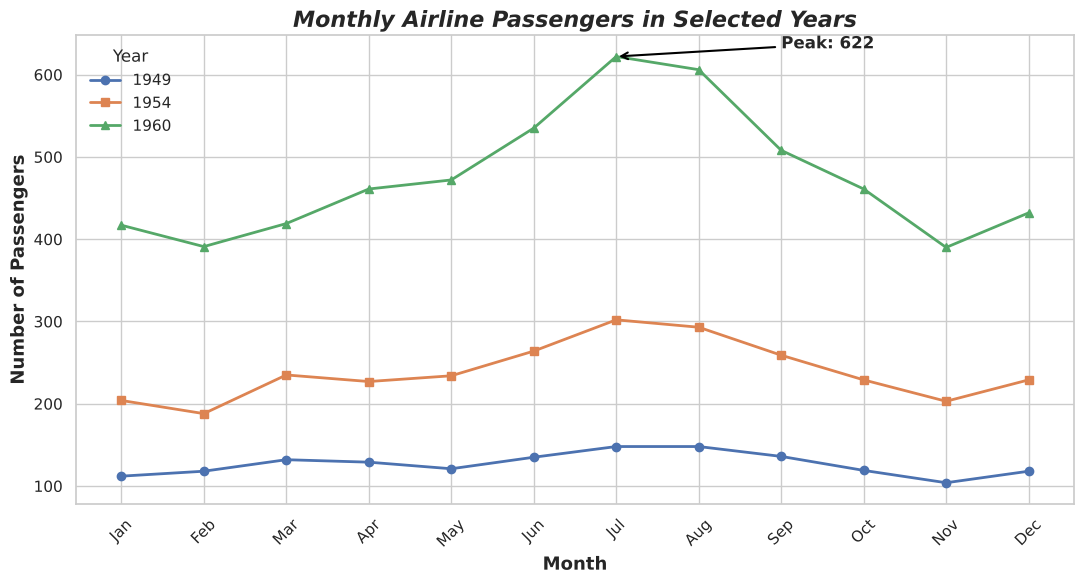

In [13]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C6 — Network Graph (2 points)
Using `networkx`, build the **campus network topology** defined by the edges below and draw it with:
- `nx.spring_layout(G, seed=7)` for the node positions
- **node size proportional to the node's degree** (e.g. `300 + 400 * degree`)
- **node color based on degree** using the colormap `'YlOrRd'`
- node labels and a title

Print the degree of every node (sorted from highest to lowest). Which device is the **hub** of the network (highest degree)?

Node Degrees (Highest to Lowest):
Switch A: 5
Core Router: 4
Switch B: 3
Switch C: 3
Firewall: 2
Web Server: 2
DB Server: 2
Internet: 1
Lab PC 1: 1
Lab PC 2: 1
Lab PC 3: 1
Printer: 1
Office PC 1: 1
Office PC 2: 1

Network Hub: Switch A


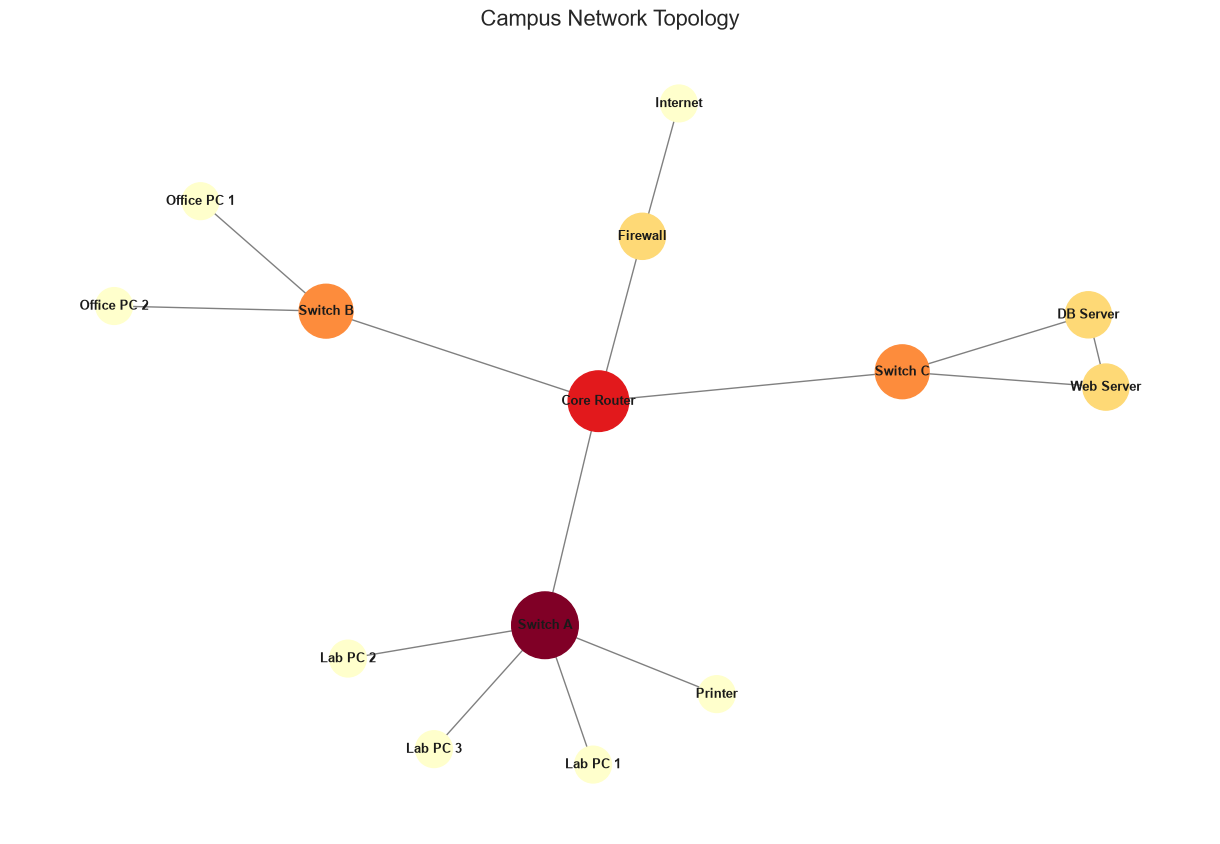

In [18]:
import networkx as nx

edges = [('Internet', 'Firewall'), ('Firewall', 'Core Router'),
         ('Core Router', 'Switch A'), ('Core Router', 'Switch B'), ('Core Router', 'Switch C'),
         ('Switch A', 'Lab PC 1'), ('Switch A', 'Lab PC 2'), ('Switch A', 'Lab PC 3'), ('Switch A', 'Printer'),
         ('Switch B', 'Office PC 1'), ('Switch B', 'Office PC 2'),
         ('Switch C', 'Web Server'), ('Switch C', 'DB Server'), ('Web Server', 'DB Server')]


import networkx as nx
import matplotlib.pyplot as plt

# Define network edges
edges = [('Internet', 'Firewall'), ('Firewall', 'Core Router'),
         ('Core Router', 'Switch A'), ('Core Router', 'Switch B'),
         ('Core Router', 'Switch C'),
         ('Switch A', 'Lab PC 1'), ('Switch A', 'Lab PC 2'),
         ('Switch A', 'Lab PC 3'), ('Switch A', 'Printer'),
         ('Switch B', 'Office PC 1'), ('Switch B', 'Office PC 2'),
         ('Switch C', 'Web Server'), ('Switch C', 'DB Server'),
         ('Web Server', 'DB Server')]

# Create graph
G = nx.Graph()
G.add_edges_from(edges)

# Calculate node degrees
degrees = dict(G.degree())

# Sort degrees from highest to lowest
sorted_degrees = sorted(degrees.items(),
                        key=lambda x: x[1], reverse=True)

print("Node Degrees (Highest to Lowest):")
for node, degree in sorted_degrees:
    print(f"{node}: {degree}")

# Identify the hub
hub = sorted_degrees[0][0]
print(f"\nNetwork Hub: {hub}")

# Set node sizes and colors based on degree
node_sizes = [300 + 400 * degrees[node] for node in G.nodes()]
node_colors = [degrees[node] for node in G.nodes()]

# Set node positions
pos = nx.spring_layout(G, seed=7)

# Draw network
plt.figure(figsize=(12, 8))

nx.draw(G, pos,
        with_labels=True,
        node_size=node_sizes,
        node_color=node_colors,
        cmap=plt.cm.YlOrRd,
        font_size=9,
        font_weight='bold',
        edge_color='gray')

plt.title('Campus Network Topology', fontsize=16)
plt.tight_layout()
plt.show()



Switch A    : 5
Core Router : 4
Switch B    : 3
Switch C    : 3
Firewall    : 2
Web Server  : 2
DB Server   : 2
Internet    : 1
Lab PC 1    : 1
Lab PC 2    : 1
Lab PC 3    : 1
Printer     : 1
Office PC 1 : 1
Office PC 2 : 1


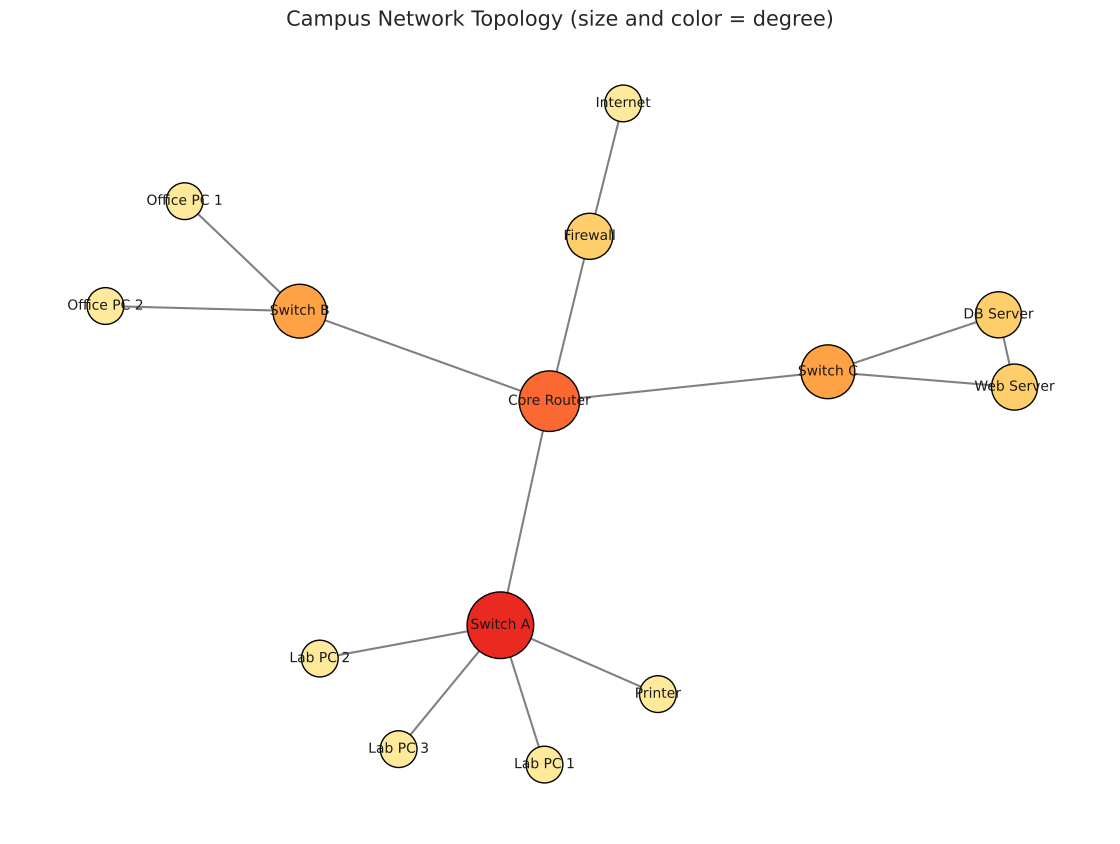

In [14]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The network hub is **Switch A**, with the highest degree of 5.

Switch A connects to the Core Router, three Lab PCs, and one Printer, making it the most connected device in the campus network.

---
## Part D — Exploratory Data Analysis

### Exercise D1 — Pearson Correlation by Formula (2 points)
A store recorded its weekly advertising budget (SAR 1000s) and weekly sales (SAR 1000s):

```python
ad_spend = [2.1, 3.5, 1.2, 4.8, 5.5, 2.9, 6.1, 3.3, 4.0, 5.0]
sales    = [24,  30,  18,  38,  41,  27,  45,  32,  33,  40]
```
1. Compute Pearson's *r* using the formula from the lecture:
$$r = \frac{N \sum xy-\sum x \sum y}{\sqrt{\left[N\sum x^2-\left(\sum x\right)^2\right]\left[N\sum y^2-\left(\sum y\right)^2\right]}}$$
   Print *r* (4 decimal places).
2. Verify your result with `df.corr(method='pearson')`.
3. Draw a scatter plot with a fitted regression line using `sns.regplot`.

Interpret the **strength** and **direction** of the relationship.

Pearson's r (Formula): 0.9933
Pearson's r (Pandas): 0.9933


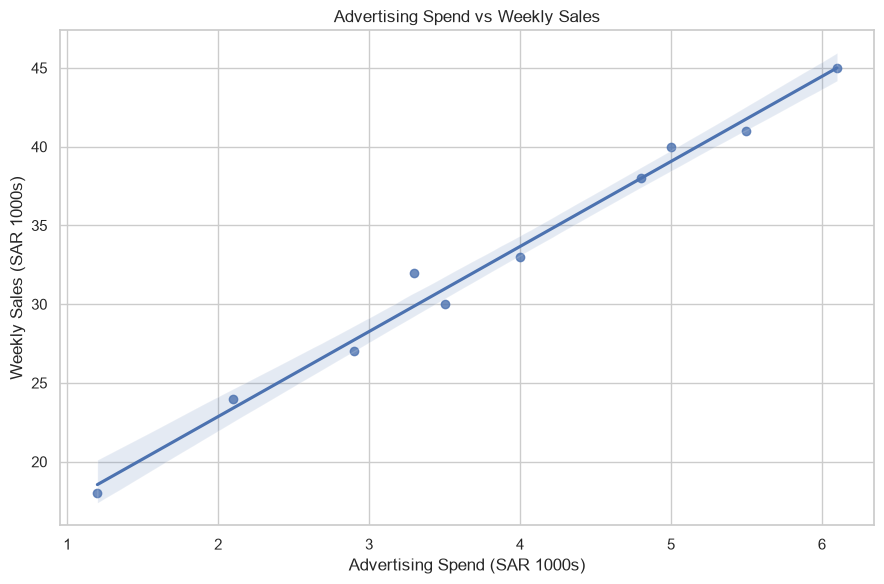

In [19]:
ad_spend = [2.1, 3.5, 1.2, 4.8, 5.5, 2.9, 6.1, 3.3, 4.0, 5.0]
sales    = [24,  30,  18,  38,  41,  27,  45,  32,  33,  40]


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Given data
ad_spend = [2.1, 3.5, 1.2, 4.8, 5.5, 2.9, 6.1, 3.3, 4.0, 5.0]
sales = [24, 30, 18, 38, 41, 27, 45, 32, 33, 40]

# Create DataFrame
df = pd.DataFrame({
    'Ad Spend': ad_spend,
    'Sales': sales
})

# 1. Calculate Pearson's r using the formula
x = np.array(ad_spend)
y = np.array(sales)
N = len(x)

numerator = N * np.sum(x * y) - np.sum(x) * np.sum(y)

denominator = np.sqrt(
    (N * np.sum(x**2) - np.sum(x)**2) *
    (N * np.sum(y**2) - np.sum(y)**2)
)

r = numerator / denominator

print(f"Pearson's r (Formula): {r:.4f}")

# 2. Verify using DataFrame correlation
r_pandas = df.corr(method='pearson').iloc[0, 1]

print(f"Pearson's r (Pandas): {r_pandas:.4f}")

# 3. Scatter plot with regression line
plt.figure(figsize=(9, 6))

sns.regplot(data=df, x='Ad Spend', y='Sales')

plt.title('Advertising Spend vs Weekly Sales')
plt.xlabel('Advertising Spend (SAR 1000s)')
plt.ylabel('Weekly Sales (SAR 1000s)')

plt.tight_layout()
plt.show()



Pearson's r (formula): 0.9933


,ad_spend,sales
ad_spend,1.000000,0.993283
sales,0.993283,1.000000


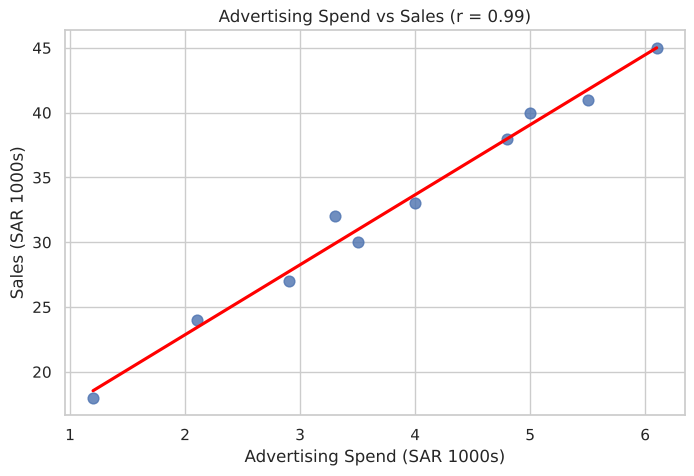

In [15]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

There is a very strong positive correlation between advertising spend and weekly sales (Pearson's r is close to +1).

This indicates that higher advertising spending is associated with higher weekly sales. The scatter plot and fitted regression line confirm a strong positive linear relationship.

### Exercise D2 — Principal Component Analysis (2 points)
Using the four numeric columns of `penguins`:
1. **Standardize** the features with `StandardScaler`.
2. Apply `PCA(n_components=2)` and add the two components to `penguins` as columns `pca1` and `pca2`.
3. Print the **variance captured** by each principal component, the total variance captured, and the **coefficients of PC1** (rounded to 3 decimals). Which original column has the largest absolute coefficient in PC1?
4. Draw a scatter plot of `pca1` vs `pca2`, colored by `species` (`hue`) with a different marker for each `sex` (`style`).

Can the first two principal components separate the three species?

Explained Variance Ratio:
PC1: 0.6863
PC2: 0.1945
Total Variance: 0.8809

PC1 Coefficients:
bill_length_mm: 0.454
bill_depth_mm: -0.399
flipper_length_mm: 0.577
body_mass_g: 0.550

Largest Absolute PC1 Coefficient: flipper_length_mm


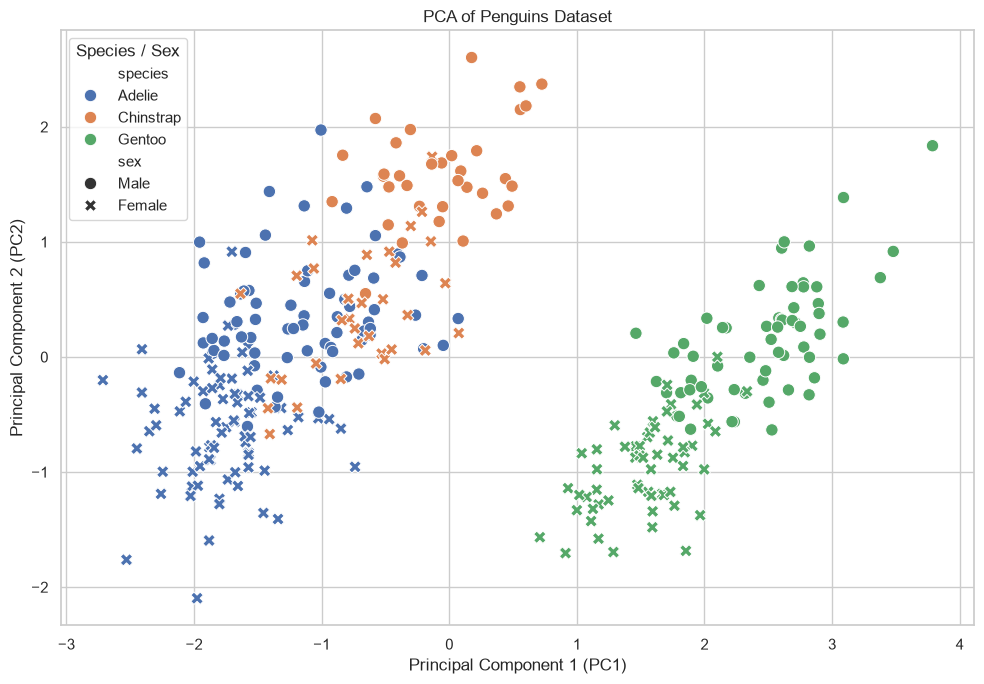

In [20]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load and clean the dataset
penguins = sns.load_dataset('penguins').dropna()

# Select the four numeric columns
numeric_cols = ['bill_length_mm', 'bill_depth_mm',
                'flipper_length_mm', 'body_mass_g']

X = penguins[numeric_cols]

# 1. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Apply PCA with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

penguins['pca1'] = X_pca[:, 0]
penguins['pca2'] = X_pca[:, 1]

# 3. Print explained variance
print("Explained Variance Ratio:")
print(f"PC1: {pca.explained_variance_ratio_[0]:.4f}")
print(f"PC2: {pca.explained_variance_ratio_[1]:.4f}")
print(f"Total Variance: {sum(pca.explained_variance_ratio_):.4f}")

# Print PC1 coefficients
print("\nPC1 Coefficients:")
for col, coef in zip(numeric_cols, pca.components_[0]):
    print(f"{col}: {coef:.3f}")

# Find the largest absolute coefficient
largest_index = np.argmax(np.abs(pca.components_[0]))
print(f"\nLargest Absolute PC1 Coefficient: {numeric_cols[largest_index]}")

# 4. PCA Scatter Plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=penguins,
    x='pca1',
    y='pca2',
    hue='species',
    style='sex',
    s=80
)

plt.title('PCA of Penguins Dataset')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend(title='Species / Sex')

plt.tight_layout()
plt.show()



Variance captured by PC1: 68.63%
Variance captured by PC2: 19.45%
Total variance captured: 88.09%

PC1 coefficients:
bill_length_mm       0.454
bill_depth_mm       -0.399
flipper_length_mm    0.577
body_mass_g          0.550

Largest absolute coefficient in PC1: flipper_length_mm


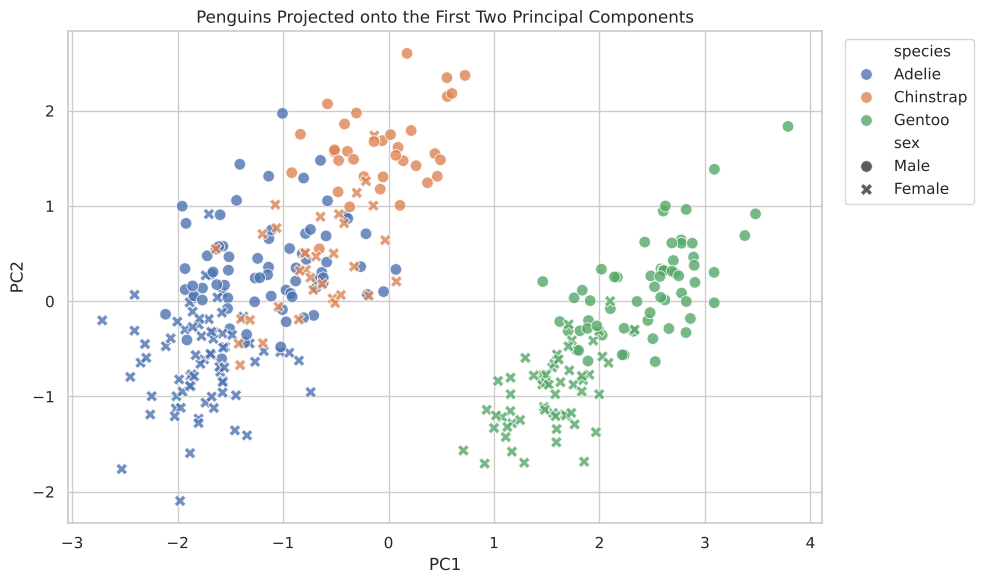

In [16]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The first two principal components provide a good separation of the three penguin species.

Gentoo penguins form a relatively distinct cluster, while Adelie and Chinstrap penguins show some overlap.

Therefore, PCA can separate the species reasonably well, but not perfectly.

### Exercise D3 — Cross Tables and Pivot Tables (2 points)
1. Create a **cross table** (`pd.crosstab`) showing the number of penguins of each `species` on each `island`, including row/column totals (`margins=True`).
2. Create a **pivot table** (`pd.pivot_table`) showing the **mean** `body_mass_g` for each `species` (rows) and `sex` (columns), rounded to 1 decimal.
3. Visualize the cross table from step 1 (without the totals) as a **heatmap** with annotated counts (`fmt='d'`, colormap `'Blues'`).

Which species lives on **all three** islands? Which island has only **one** species?

Cross Table - Species by Island:


island,Biscoe,Dream,Torgersen,All
species,,,,
Adelie,44,55,47,146
Chinstrap,0,68,0,68
Gentoo,119,0,0,119
All,163,123,47,333



Pivot Table - Mean Body Mass by Species and Sex:


sex,Female,Male
species,,
Adelie,3368.8,4043.5
Chinstrap,3527.2,3939.0
Gentoo,4679.7,5484.8


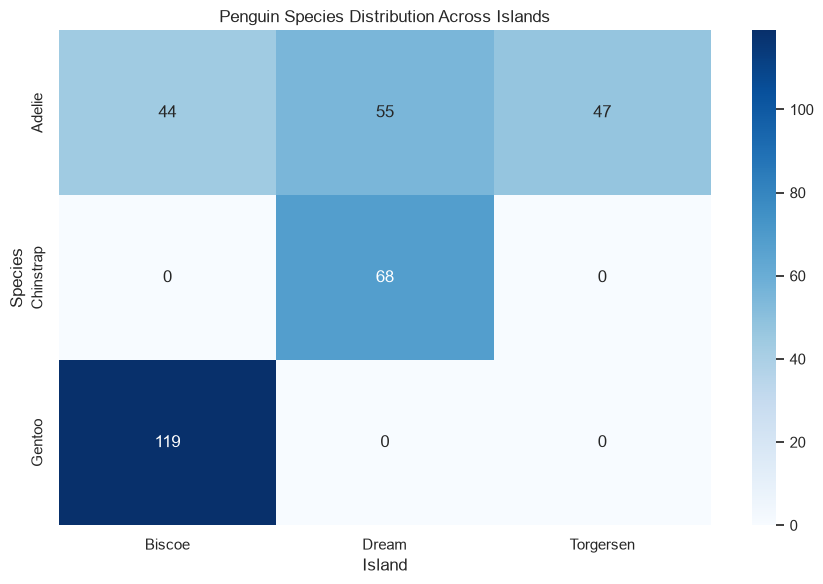

In [21]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean the dataset
penguins = sns.load_dataset('penguins').dropna()

# 1. Create cross table with totals
cross_table = pd.crosstab(
    penguins['species'],
    penguins['island'],
    margins=True
)

print("Cross Table - Species by Island:")
display(cross_table)

# 2. Create pivot table for mean body mass
pivot_table = pd.pivot_table(
    penguins,
    values='body_mass_g',
    index='species',
    columns='sex',
    aggfunc='mean'
).round(1)

print("\nPivot Table - Mean Body Mass by Species and Sex:")
display(pivot_table)

# 3. Heatmap without totals
plt.figure(figsize=(9, 6))

sns.heatmap(
    cross_table.drop(index='All', columns='All'),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Penguin Species Distribution Across Islands')
plt.xlabel('Island')
plt.ylabel('Species')

plt.tight_layout()
plt.show()



island,Biscoe,Dream,Torgersen,All
species,,,,
Adelie,44,55,47,146
Chinstrap,0,68,0,68
Gentoo,119,0,0,119
All,163,123,47,333


sex,Female,Male
species,,
Adelie,3368.8,4043.5
Chinstrap,3527.2,3939.0
Gentoo,4679.7,5484.8


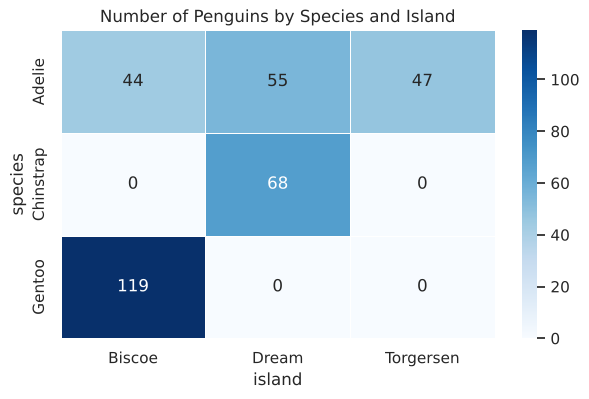

In [17]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

**Adelie** is the only penguin species found on all three islands (Biscoe, Dream, and Torgersen).

**Torgersen** is the only island that has just one species, Adelie.

### Exercise D4 — Violin Plot (2 points)
Draw a Seaborn **violin plot** of `body_mass_g` (y) for each `island` (x), split by `sex` (`hue='sex'`, `split=True`) and showing the quartiles inside (`inner='quart'`). Add a title and axis labels.

What information does a violin plot show that a box plot does not?

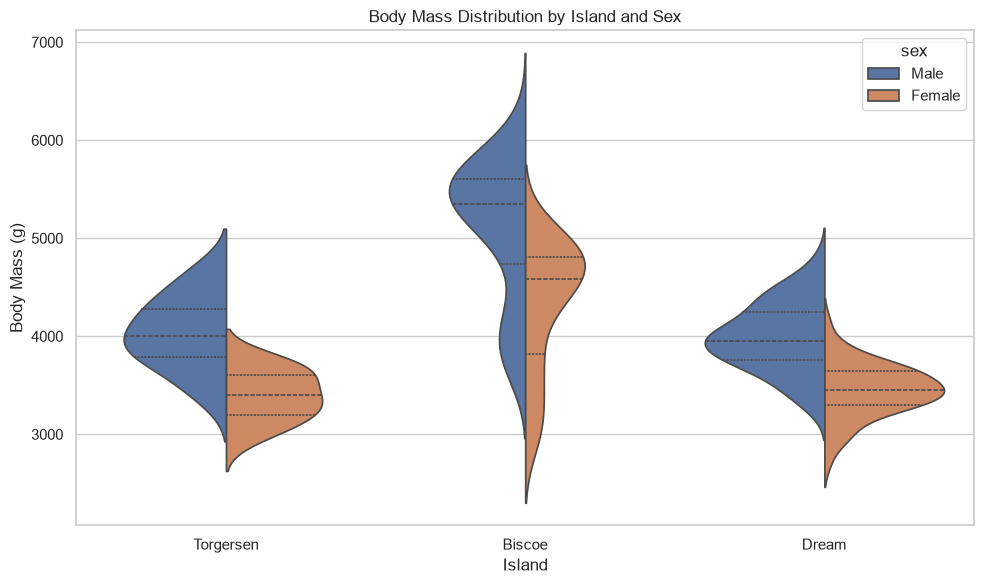

In [22]:

import seaborn as sns
import matplotlib.pyplot as plt

# Load and clean the dataset
penguins = sns.load_dataset('penguins').dropna()

# Create violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=penguins,
    x='island',
    y='body_mass_g',
    hue='sex',
    split=True,
    inner='quart'
)

# Add title and axis labels
plt.title('Body Mass Distribution by Island and Sex')
plt.xlabel('Island')
plt.ylabel('Body Mass (g)')

plt.tight_layout()
plt.show()



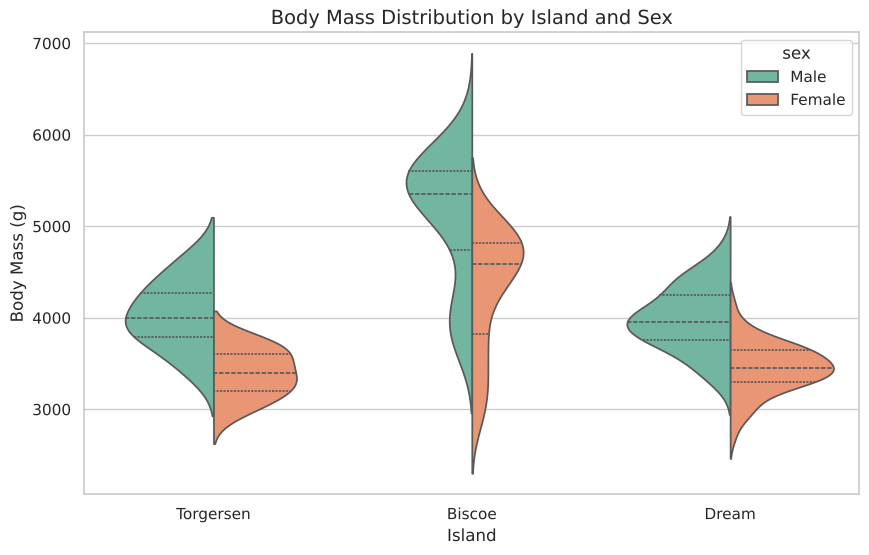

In [18]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

A violin plot shows the shape and density of the data distribution, which a box plot does not.

It reveals where values are concentrated, whether the distribution is skewed, and whether there are multiple peaks. It also displays quartiles, allowing comparison of body mass distributions between males and females across islands.

### Exercise D5 — Pair Plot (2 points)
Create a Seaborn **pair plot** of the four numeric measurement columns, colored by `species`, using `corner=True` and `diag_kind='kde'`. Add an overall title with `plt.suptitle(..., y=1.02)`.

Which **single** pair of variables best separates all three species?

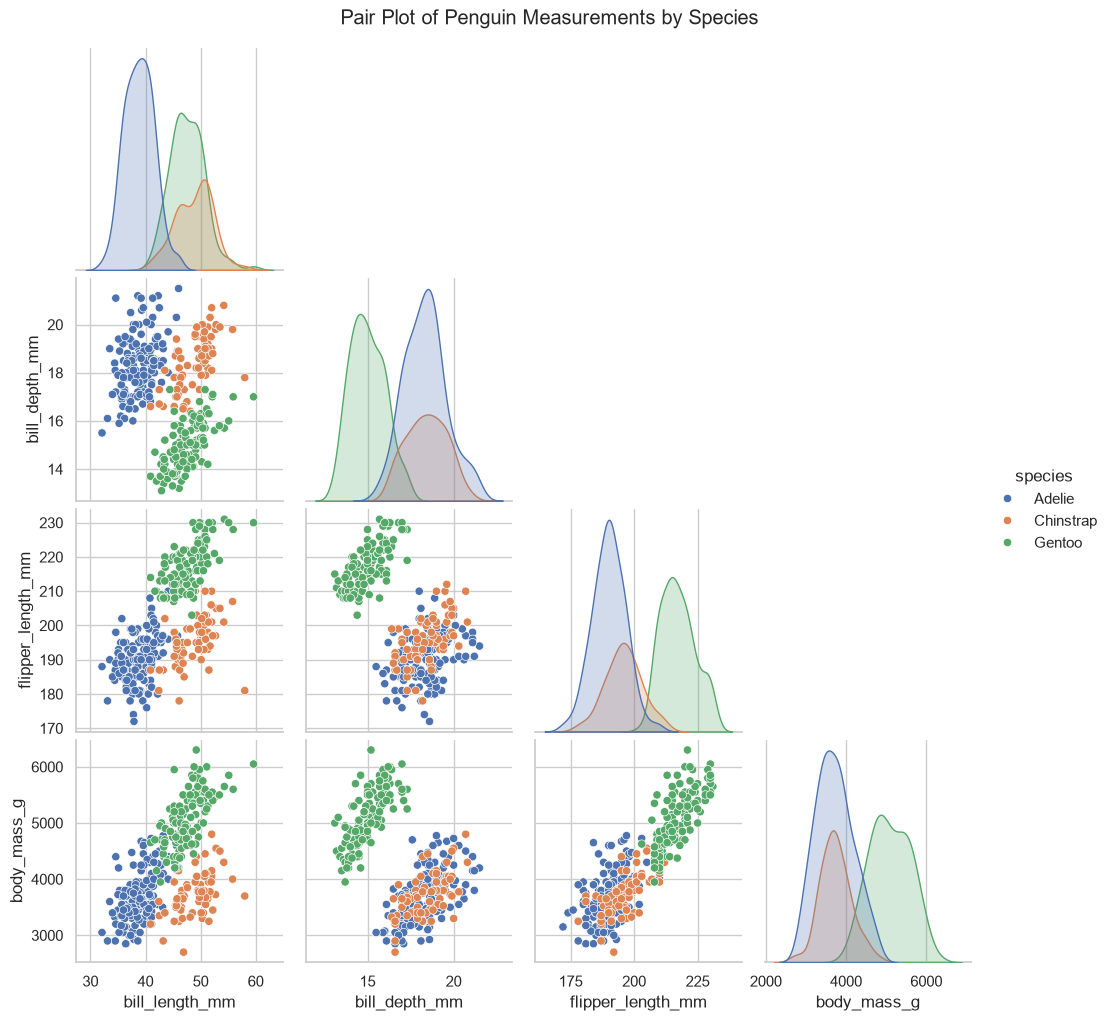

In [23]:

import seaborn as sns
import matplotlib.pyplot as plt

# Load and clean the dataset
penguins = sns.load_dataset('penguins').dropna()

# Select four numeric measurement columns
numeric_cols = ['bill_length_mm', 'bill_depth_mm',
                'flipper_length_mm', 'body_mass_g']

# Create pair plot
g = sns.pairplot(
    data=penguins,
    vars=numeric_cols,
    hue='species',
    corner=True,
    diag_kind='kde'
)

# Add overall title
plt.suptitle('Pair Plot of Penguin Measurements by Species', y=1.02)

plt.show()



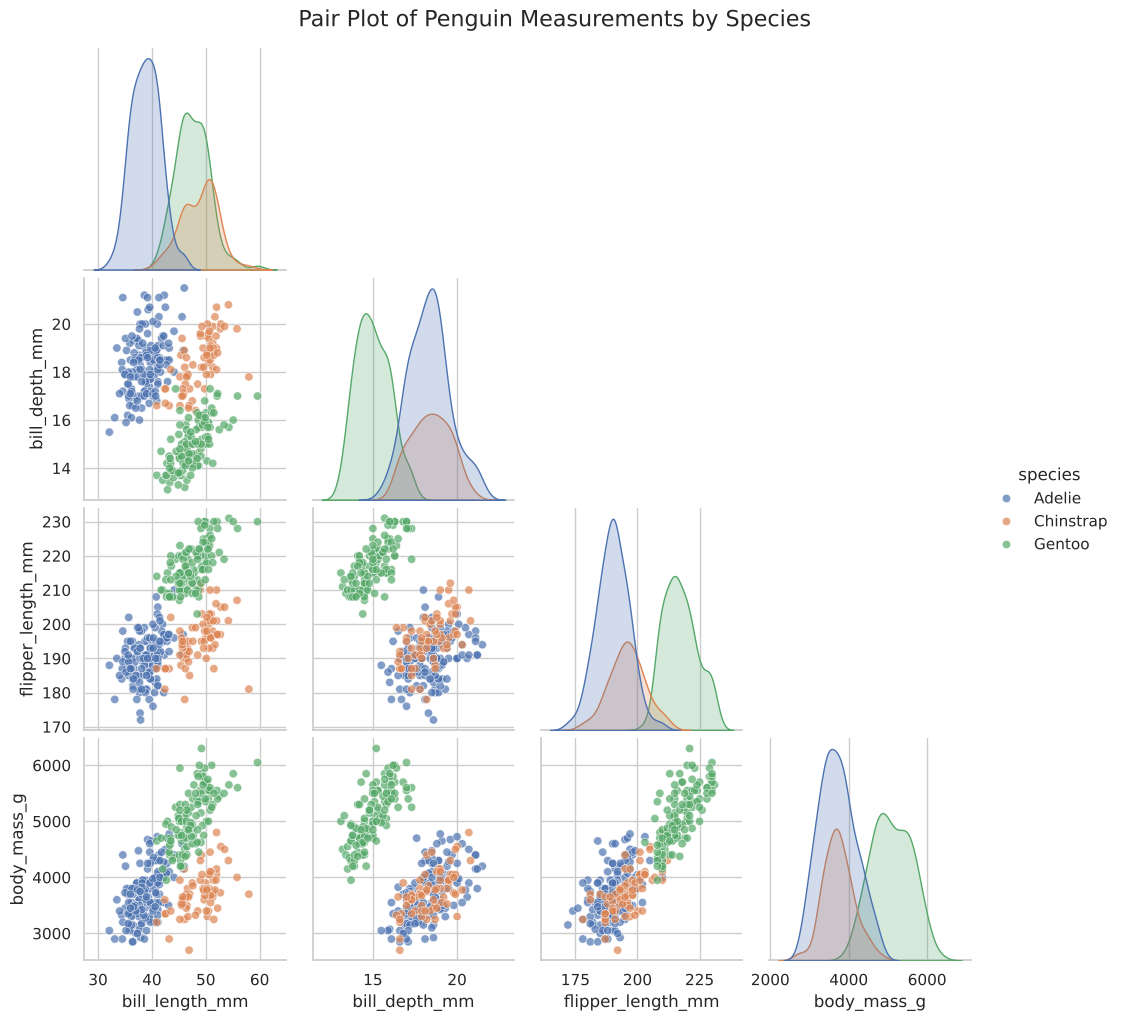

In [19]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The pair of variables that best separates all three penguin species is **bill_length_mm and bill_depth_mm**.

These two measurements show relatively distinct clusters for Adelie, Chinstrap, and Gentoo penguins, although some overlap exists.

---
## Part E — Visualizing and Analyzing Time Series Data (Flights Dataset)

Run the cell below to turn the `flights` dataset into a **monthly time series** `ts` with a `DatetimeIndex` (January 1949 to December 1960).

In [24]:
flights = sns.load_dataset('flights')
flights['date'] = pd.date_range(start='1949-01-01', periods=len(flights), freq='MS')
ts = flights.set_index('date')['passengers'].asfreq('MS')
ts.head()

date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64

### Exercise E1 — Moving Averages and Smoothing (2 points)
On one figure (`figsize=(12, 6)`), plot:
- the original series `ts`
- its **12-month Simple Moving Average (SMA)** using `.rolling(window=12).mean()`
- its **12-month Exponential Moving Average (EMA)** using `.ewm(span=12, adjust=False).mean()`

Use different colors and line widths, and add a legend, axis labels and a title.

Why does the SMA line start 11 months later than the original data, and which of the two averages reacts faster to changes?

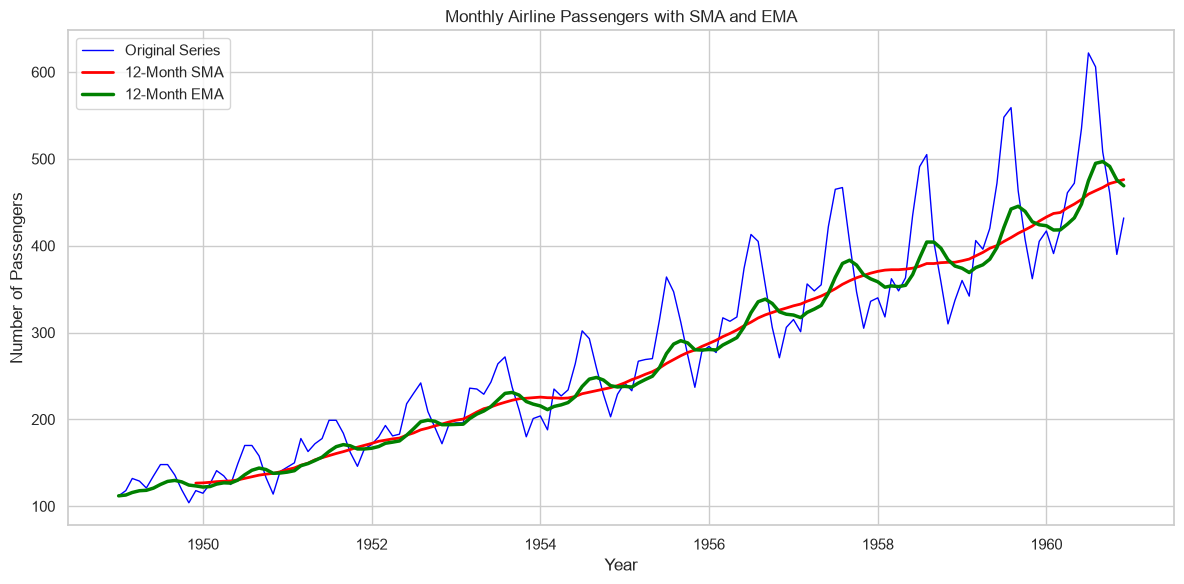

In [25]:

import pandas as pd
import matplotlib.pyplot as plt

# Calculate 12-month moving averages
sma_12 = ts.rolling(window=12).mean()
ema_12 = ts.ewm(span=12, adjust=False).mean()

# Create figure
plt.figure(figsize=(12, 6))

# Plot original time series
plt.plot(ts.index, ts, color='blue',
         linewidth=1, label='Original Series')

# Plot Simple Moving Average
plt.plot(sma_12.index, sma_12, color='red',
         linewidth=2, label='12-Month SMA')

# Plot Exponential Moving Average
plt.plot(ema_12.index, ema_12, color='green',
         linewidth=2.5, label='12-Month EMA')

# Add labels and title
plt.title('Monthly Airline Passengers with SMA and EMA')
plt.xlabel('Year')
plt.ylabel('Number of Passengers')

plt.legend()
plt.tight_layout()
plt.show()



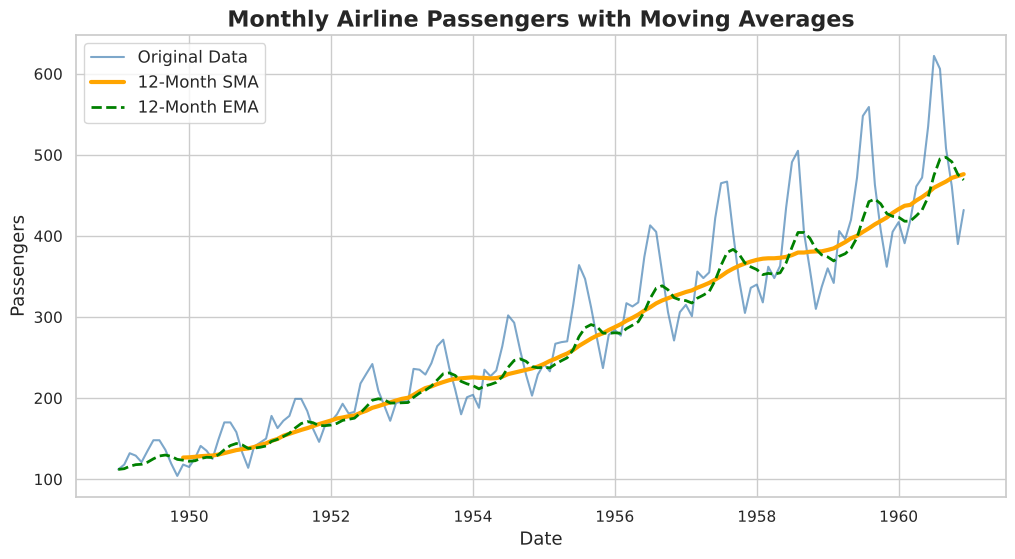

In [21]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The SMA starts 11 months later because it requires 12 observations to calculate the first average.

The EMA reacts faster to changes because it gives more weight to recent observations, while the SMA assigns equal weight to all observations within the 12-month window.

### Exercise E2 — Bar Chart and Stacked Area Chart (2 points)
Create one figure with **two subplots** (1 × 2, `figsize=(16, 6)`):
- **Left:** a **bar chart** of the **total passengers per year**.
- **Right:** a **stacked area chart** of the **total passengers per quarter** (Q1–Q4) for each year, with a legend.

*Hint:* `ts.groupby([ts.index.year, ts.index.quarter]).sum().unstack()` gives a table with one row per year and one column per quarter.

Which quarter contributes the most passengers every year?

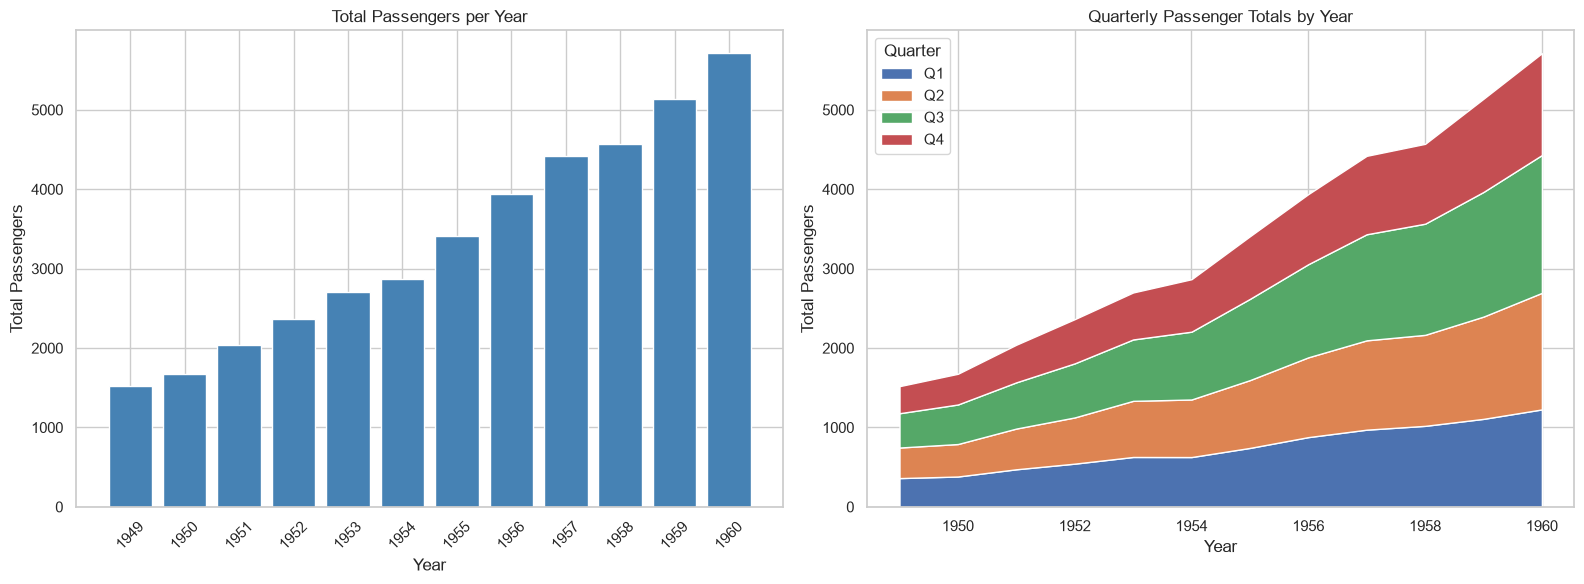

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

# Calculate total passengers per year
yearly_total = ts.groupby(ts.index.year).sum()

# Calculate total passengers per quarter for each year
quarterly_total = ts.groupby(
    [ts.index.year, ts.index.quarter]
).sum().unstack()

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Bar chart
axes[0].bar(yearly_total.index, yearly_total.values, color='steelblue')
axes[0].set_title('Total Passengers per Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Total Passengers')
axes[0].set_xticks(yearly_total.index)
axes[0].tick_params(axis='x', rotation=45)

# Right: Stacked area chart
axes[1].stackplot(
    quarterly_total.index,
    quarterly_total[1],
    quarterly_total[2],
    quarterly_total[3],
    quarterly_total[4],
    labels=['Q1', 'Q2', 'Q3', 'Q4']
)

axes[1].set_title('Quarterly Passenger Totals by Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Total Passengers')
axes[1].legend(title='Quarter', loc='upper left')

plt.tight_layout()
plt.show()



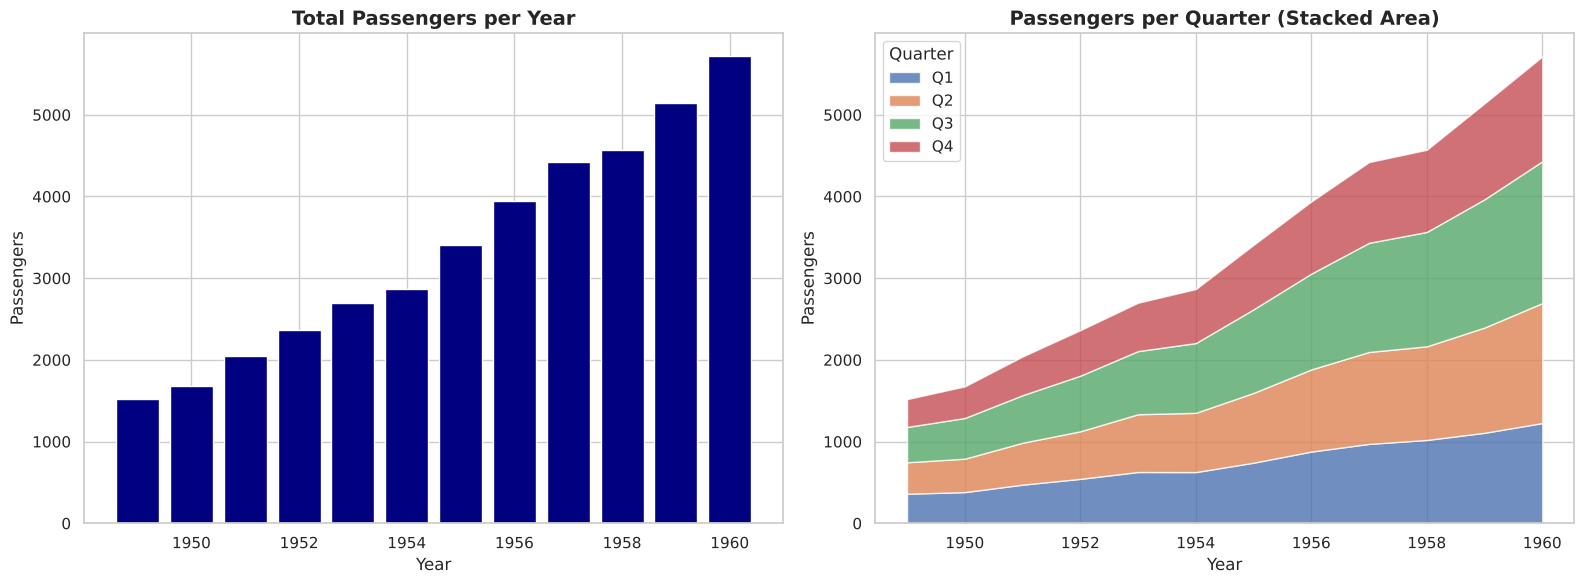

In [22]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

**Q3 (July–September)** contributes the most passengers every year.

This indicates that passenger traffic is highest during the summer months, reflecting a seasonal pattern in air travel demand.

### Exercise E3 — Trend Analysis (2 points)
Fit two trend models to `ts`, using the month number `X = np.arange(len(ts)).reshape(-1, 1)` as the input:
1. A **linear trend** with `LinearRegression`
2. A **polynomial trend of degree 2** with `PolynomialFeatures` + `LinearRegression`

Plot the original series with both trend lines on the same axes and add a legend. Print the slope of the linear trend (passengers gained per month).

Linear Trend Slope: 2.66 passengers per month


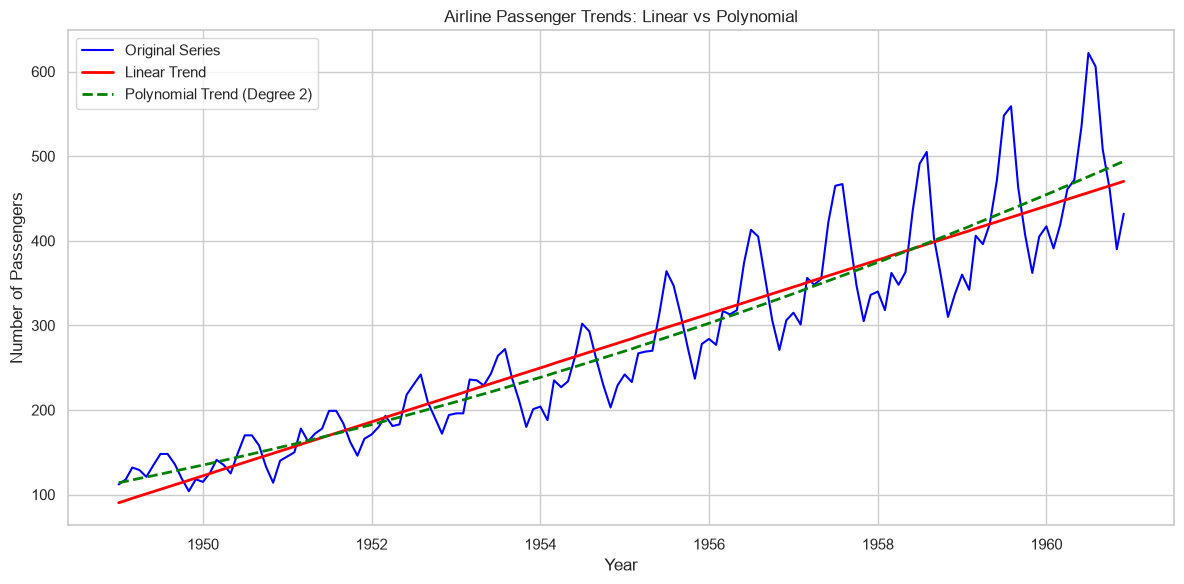

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures


import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# Create month numbers
X = np.arange(len(ts)).reshape(-1, 1)
y = ts.values.ravel()

# 1. Linear trend
linear_model = LinearRegression()
linear_model.fit(X, y)
linear_trend = linear_model.predict(X)

# 2. Polynomial trend (degree 2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

poly_model = LinearRegression()
poly_model.fit(X_poly, y)
poly_trend = poly_model.predict(X_poly)

# Print linear trend slope
print(f"Linear Trend Slope: {linear_model.coef_[0]:.2f} passengers per month")

# Plot original series and trend lines
plt.figure(figsize=(12, 6))

plt.plot(ts.index, y, color='blue',
         linewidth=1.5, label='Original Series')

plt.plot(ts.index, linear_trend, color='red',
         linewidth=2, label='Linear Trend')

plt.plot(ts.index, poly_trend, color='green',
         linewidth=2, linestyle='--',
         label='Polynomial Trend (Degree 2)')

plt.title('Airline Passenger Trends: Linear vs Polynomial')
plt.xlabel('Year')
plt.ylabel('Number of Passengers')

plt.legend()
plt.tight_layout()
plt.show()



Linear trend slope: 2.66 passengers per month


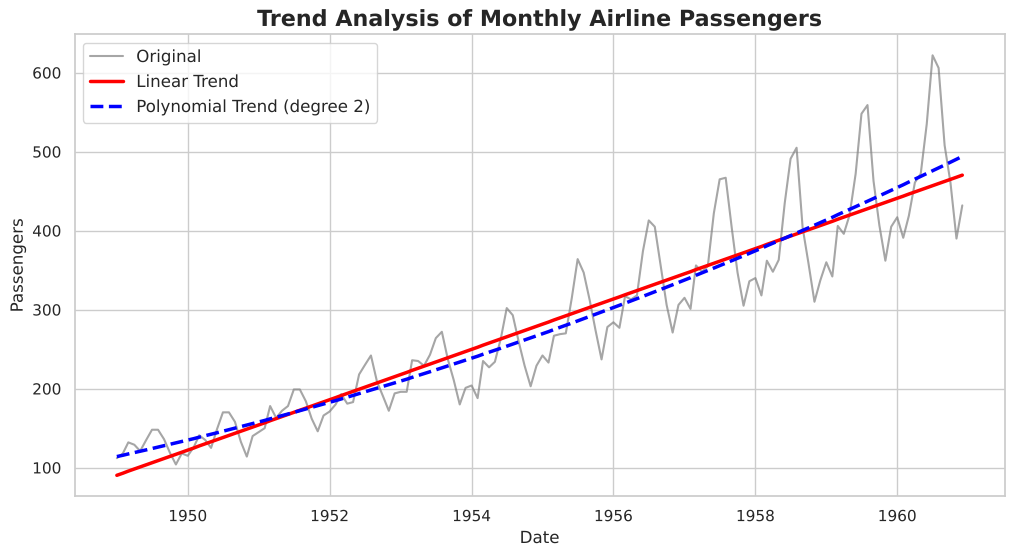

In [23]:
# The output generated by the code written to answer this question should be as follows:

### Exercise E4 — Seasonal Decomposition (2 points)
Apply **STL decomposition** (`from statsmodels.tsa.seasonal import STL`) to `ts` with `seasonal=13` and plot the result (`result.plot()`). Set the figure size to `(12, 8)`.

Look at the **seasonal** component. Does the size of the seasonal swings stay constant or grow over time? Based on this, would an **additive** or a **multiplicative** model describe this series better?

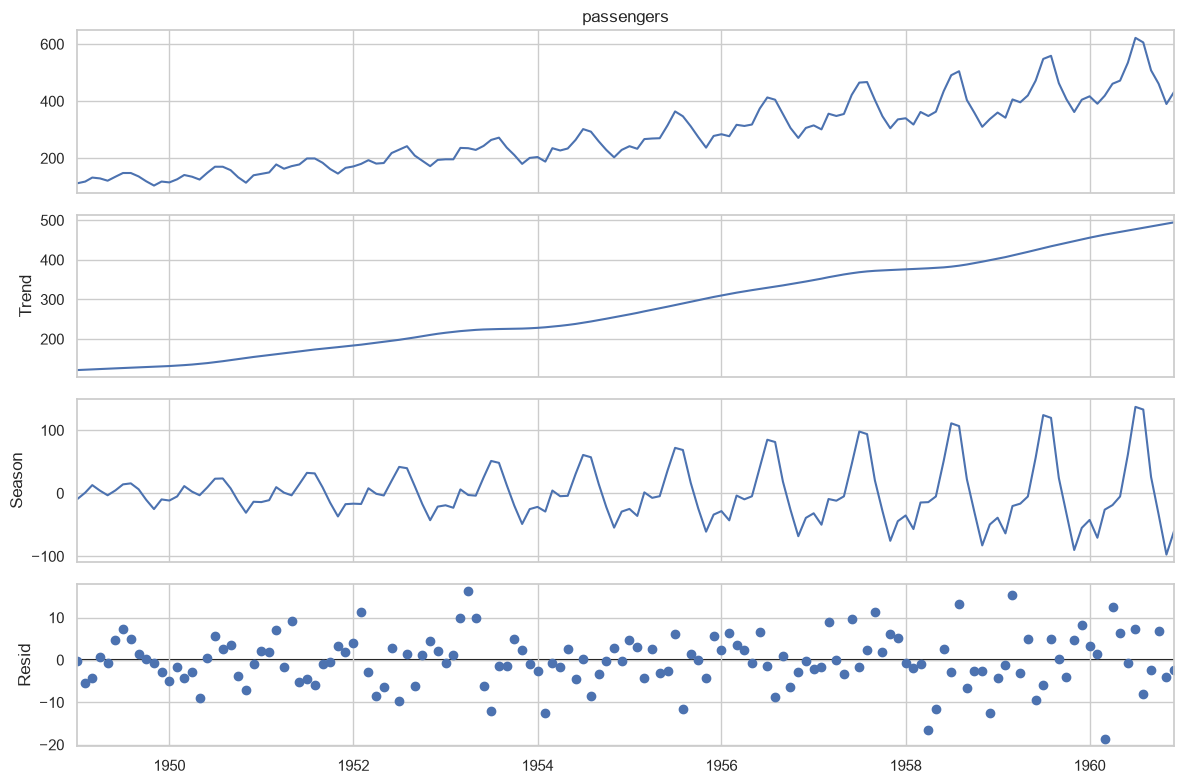

In [28]:
from statsmodels.tsa.seasonal import STL


import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

# Apply STL decomposition
stl = STL(ts, period=12, seasonal=13)
result = stl.fit()

# Plot decomposition
fig = result.plot()
fig.set_size_inches(12, 8)

plt.tight_layout()
plt.show()



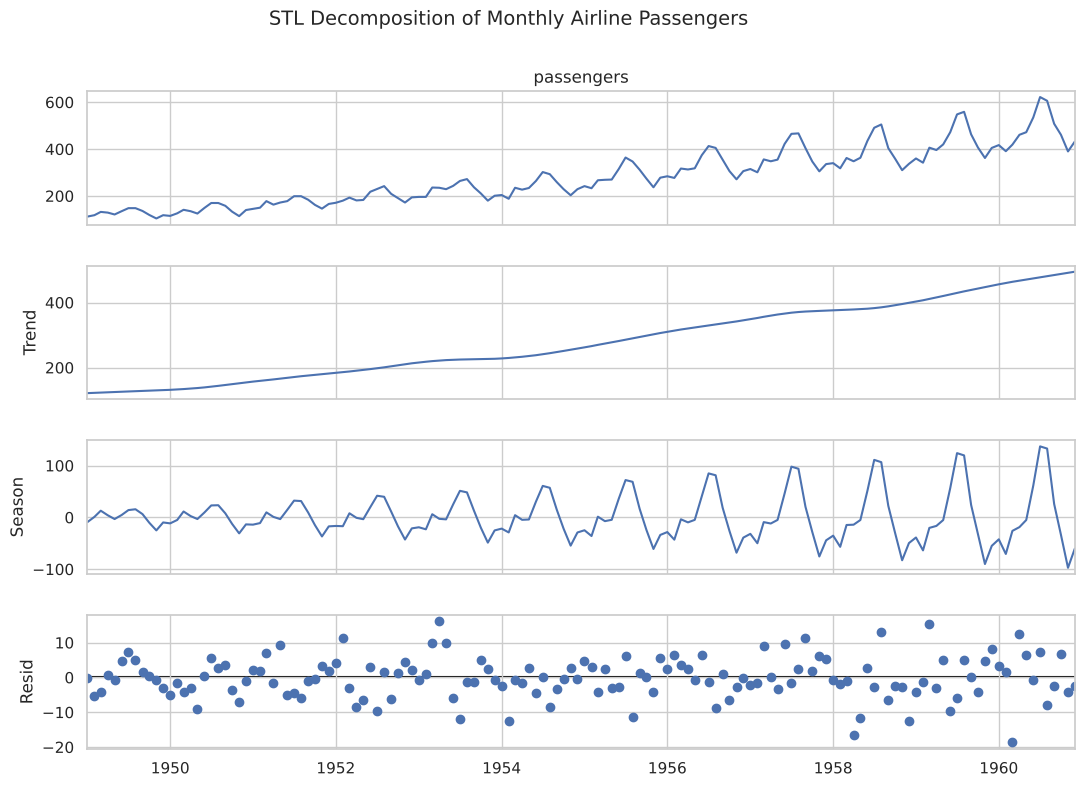

In [24]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The seasonal swings grow larger over time as the number of passengers increases.

A **multiplicative model** would describe this series better because the seasonal variation increases with the overall level of the time series, rather than remaining constant.

### Exercise E5 — Stationarity and Differencing (2 points)
Use the **Augmented Dickey-Fuller test** (`from statsmodels.tsa.stattools import adfuller`) to check the stationarity of:
1. the original series `ts`
2. the **first difference** `ts.diff().dropna()`
3. the **first + seasonal (lag-12) difference** `ts.diff().diff(12).dropna()`

For each series, print the ADF statistic, the p-value and whether it is stationary at α = 0.05. Then plot the three series in a **3 × 1 subplot** grid (`figsize=(12, 10)`) with a title on each panel.

Original Series:
ADF Statistic: 0.8154
P-value: 0.9919
Stationary at α = 0.05: No

First Difference:
ADF Statistic: -2.8293
P-value: 0.0542
Stationary at α = 0.05: No

First + Seasonal Difference:
ADF Statistic: -15.5956
P-value: 0.0000
Stationary at α = 0.05: Yes



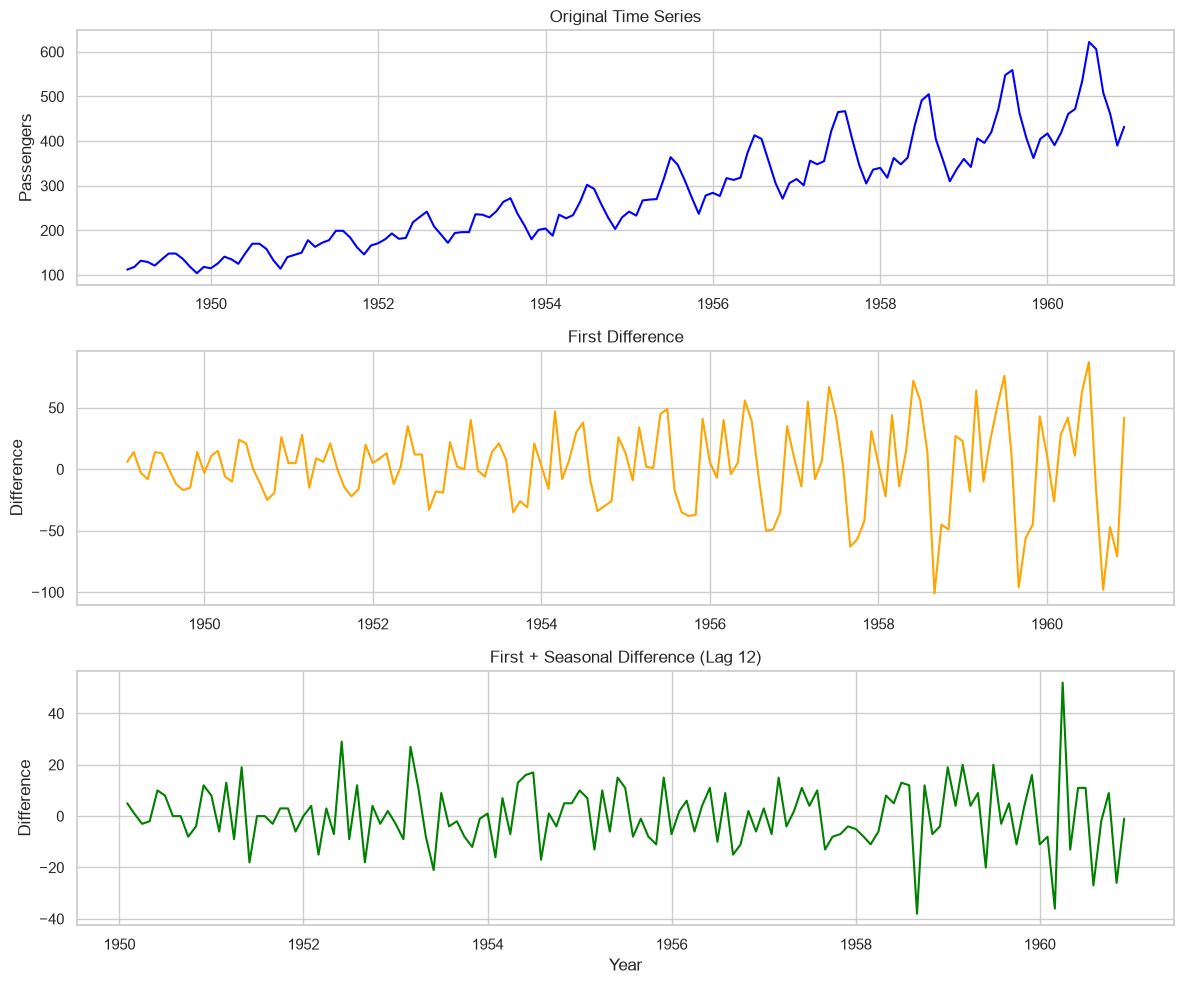

In [29]:
from statsmodels.tsa.stattools import adfuller


import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Prepare the three series
original = ts
first_diff = ts.diff().dropna()
seasonal_diff = ts.diff().diff(12).dropna()

# Function to perform ADF test
def adf_test(series, name):
    result = adfuller(series)
    adf_stat = result[0]
    p_value = result[1]

    print(f"{name}:")
    print(f"ADF Statistic: {adf_stat:.4f}")
    print(f"P-value: {p_value:.4f}")
    print(f"Stationary at α = 0.05: {'Yes' if p_value < 0.05 else 'No'}")
    print()

# Run ADF tests
adf_test(original, "Original Series")
adf_test(first_diff, "First Difference")
adf_test(seasonal_diff, "First + Seasonal Difference")

# Plot the three series
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(original, color='blue')
axes[0].set_title('Original Time Series')
axes[0].set_ylabel('Passengers')

axes[1].plot(first_diff, color='orange')
axes[1].set_title('First Difference')
axes[1].set_ylabel('Difference')

axes[2].plot(seasonal_diff, color='green')
axes[2].set_title('First + Seasonal Difference (Lag 12)')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Difference')

plt.tight_layout()
plt.show()



Original Series                    ADF =   0.815   p-value = 0.9919   -> Non-stationary
First Difference                   ADF =  -2.829   p-value = 0.0542   -> Non-stationary
First + Seasonal (12) Difference   ADF = -15.596   p-value = 0.0000   -> Stationary


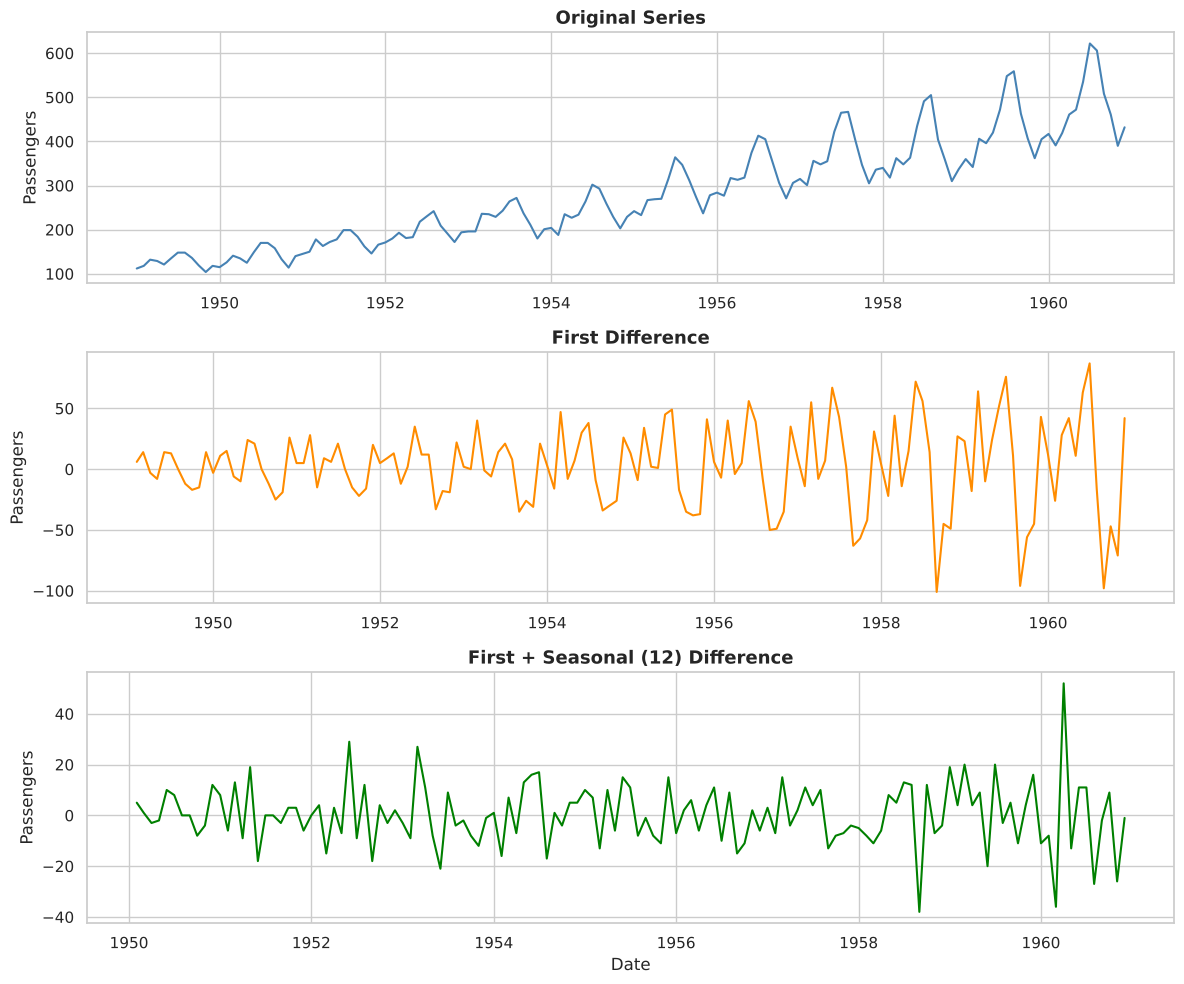

In [25]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The original time series is non-stationary because it contains an increasing trend and strong seasonality.

The first difference removes part of the trend, but seasonal patterns remain, so the series is still non-stationary.

After applying both first and seasonal (lag-12) differencing, the series becomes stationary at α = 0.05 (p-value < 0.05). This shows that both trend and seasonality need to be addressed to achieve stationarity.

### Exercise E6 — Forecasting with ETS and ARIMA (3 points)
1. Split `ts` into a **training set** (1949–1958) and a **test set** (1959–1960): `train = ts[:'1958']`, `test = ts['1959':]`.
2. Fit an **Exponential Smoothing (ETS)** model (`from statsmodels.tsa.holtwinters import ExponentialSmoothing`) with `trend='add'`, `seasonal='mul'`, `seasonal_periods=12`, and forecast the next **24 months**.
3. Fit an **ARIMA(1, 1, 1)** model (`from statsmodels.tsa.arima.model import ARIMA`) and forecast the next 24 months, including the **95% confidence interval** (`get_forecast(...).conf_int()`).
4. Plot the training data, the actual test data, both forecasts, and the ARIMA confidence interval as a shaded band (`plt.fill_between`) on one figure (`figsize=(14, 7)`) with a legend.
5. Compute and print the **Mean Absolute Error (MAE)** of each model on the test set.

Which model forecasts better, and why?

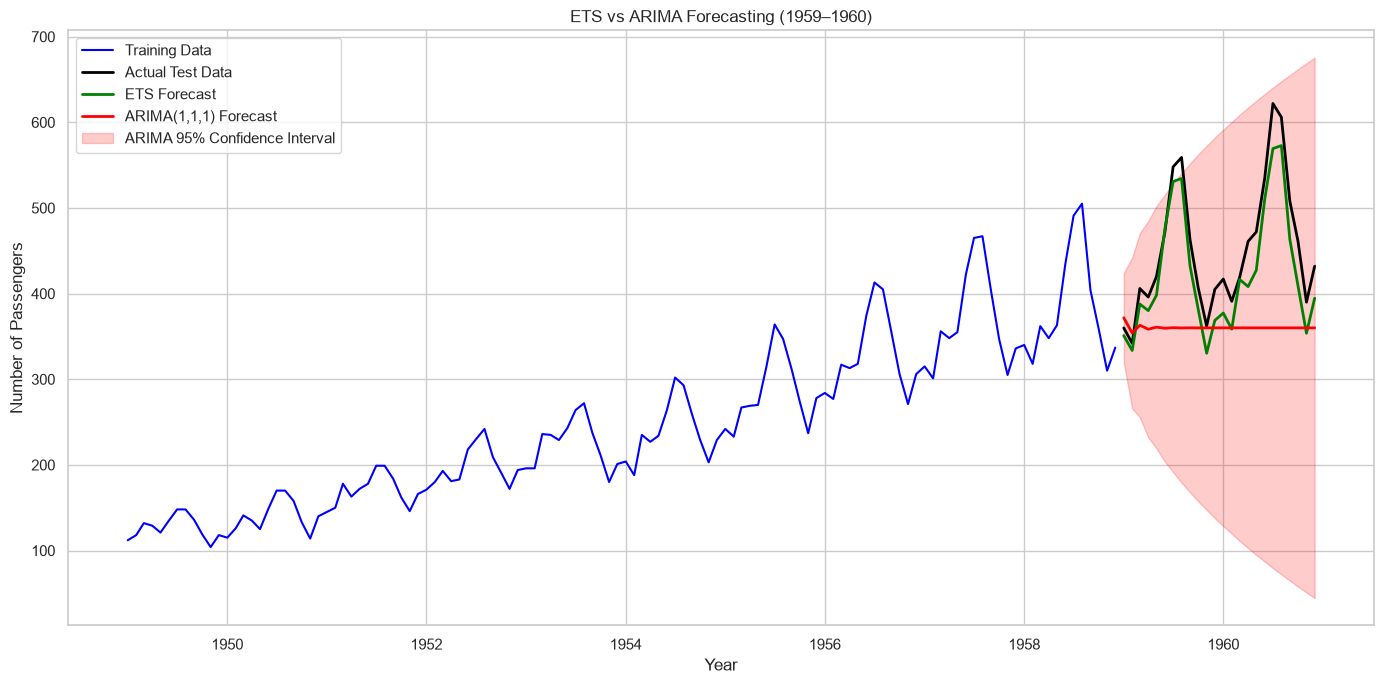

ETS MAE: 28.98
ARIMA MAE: 93.90
Better Forecasting Model: ETS


In [30]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA


import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

# 1. Split data into training and test sets
train = ts[:'1958']
test = ts['1959':]

# 2. Fit ETS model
ets_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='mul',
    seasonal_periods=12
).fit()

ets_forecast = ets_model.forecast(24)

# 3. Fit ARIMA(1, 1, 1) model
arima_model = ARIMA(train, order=(1, 1, 1)).fit()

arima_result = arima_model.get_forecast(steps=24)
arima_forecast = arima_result.predicted_mean
arima_ci = arima_result.conf_int(alpha=0.05)

# 4. Plot actual data and forecasts
plt.figure(figsize=(14, 7))

plt.plot(train.index, train, label='Training Data',
         color='blue', linewidth=1.5)

plt.plot(test.index, test, label='Actual Test Data',
         color='black', linewidth=2)

plt.plot(ets_forecast.index, ets_forecast,
         label='ETS Forecast', color='green',
         linewidth=2)

plt.plot(arima_forecast.index, arima_forecast,
         label='ARIMA(1,1,1) Forecast', color='red',
         linewidth=2)

# ARIMA 95% confidence interval
plt.fill_between(
    arima_forecast.index,
    arima_ci.iloc[:, 0],
    arima_ci.iloc[:, 1],
    color='red',
    alpha=0.2,
    label='ARIMA 95% Confidence Interval'
)

plt.title('ETS vs ARIMA Forecasting (1959–1960)')
plt.xlabel('Year')
plt.ylabel('Number of Passengers')
plt.legend()
plt.tight_layout()
plt.show()

# 5. Calculate MAE
ets_mae = mean_absolute_error(test, ets_forecast)
arima_mae = mean_absolute_error(test, arima_forecast)

print(f"ETS MAE: {ets_mae:.2f}")
print(f"ARIMA MAE: {arima_mae:.2f}")

# Identify the better model
if ets_mae < arima_mae:
    print("Better Forecasting Model: ETS")
elif arima_mae < ets_mae:
    print("Better Forecasting Model: ARIMA")
else:
    print("Both models have the same MAE")



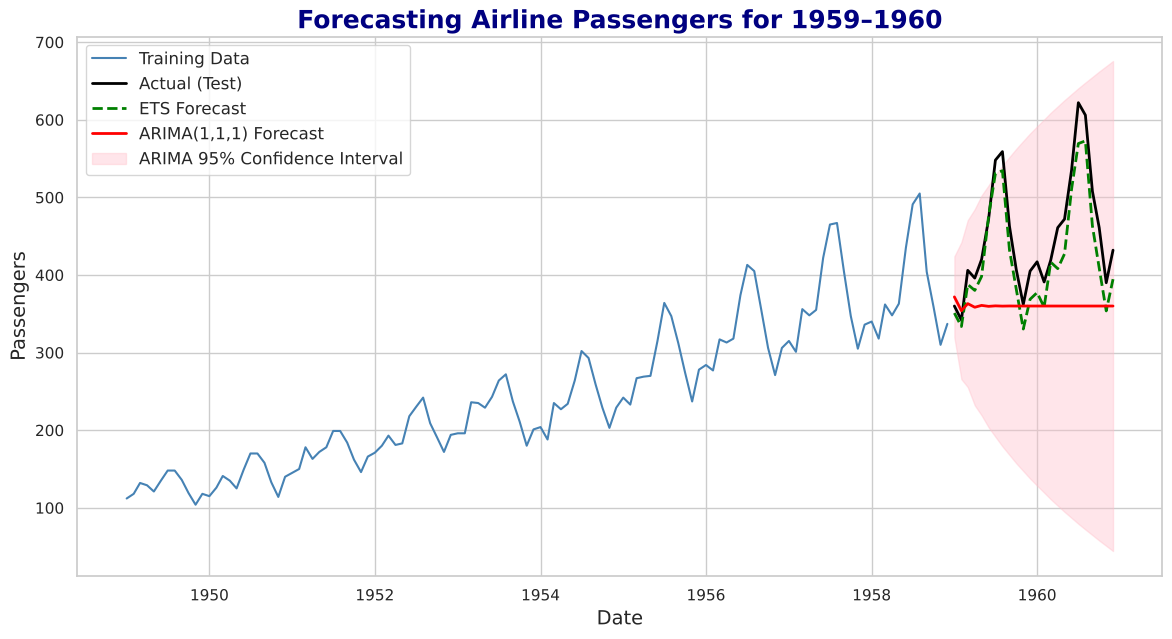

ETS   MAE: 28.98
ARIMA MAE: 93.90


In [26]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

The **ETS model** is expected to forecast better than ARIMA(1,1,1), as it explicitly captures both the trend and the multiplicative seasonal patterns in airline passenger data.

ARIMA(1,1,1) does not include a seasonal component, so it may struggle to predict the recurring seasonal fluctuations.

The model with the **lower MAE** provides the more accurate forecasts on the test set.

---
## End of Assignment